# Subject-independent transfer + denoising

## Цель

Проверить, насколько transfer learning и denoising помогают классификации
motor imagery на субъектах, которых classifier не видел во время обучения.

Эксперимент проводится независимо на двух датасетах:

- BCI Competition IV 2a
- PhysioNet EEG Motor Movement/Imagery Dataset

Для обоих датасетов используется subject-independent protocol.

---

## Основные факторы

### Classifier

Сравниваются:

1. EEGNet baseline — обучение с нуля
2. EEGNet transfer — инициализация backbone весами Cho2017

### Signal condition

Каждый classifier оценивается на:

1. Clean
2. Clean → Denoiser
3. Noisy -5 dB
4. Noisy -5 dB → Denoiser

---

## Главные вопросы

### Transfer learning

Повышает ли Cho-pretraining accuracy на unseen subjects?

### Denoising

Восстанавливает ли denoiser downstream classification accuracy
после добавления артефакта?

### Clean preservation

Не ухудшает ли denoiser уже чистый EEG?

### Dataset generality

Повторяются ли эффекты transfer и denoising
на BCI IV 2a и PhysioNet?

# Subject-independent protocol

## BCI IV 2a

Используется Leave-One-Subject-Out:

```text
Fold 1:
train/validation = A02–A09
test             = A01

Fold 2:
train/validation = A01, A03–A09
test             = A02

...

Fold 9:
train/validation = A01–A08
test             = A09

Held-out subject не участвует:
- в classifier training;
- в validation/model selection;
- в denoiser training.



## PhysioNet
Для PhysioNet используется subject-wise cross-validation.
Все trials одного человека принадлежат только одному split.
Subjects разбиваются на 5 folds.
На каждой итерации:
4 folds → train/validation
1 fold  → unseen test subjects

Такой дизайн позволяет оценить subject-independent generalization,
не обучая отдельную модель 109 раз.

In [1]:
# ============================================================
# 1. IMPORTS
# ============================================================

import os
import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import loadmat
from scipy.stats import wilcoxon

from sklearn.model_selection import (
    train_test_split,
    GroupKFold,
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    cohen_kappa_score,
)

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    TensorDataset,
    DataLoader,
)

import mne

In [2]:
# ============================================================
# 2. GLOBAL CONFIG
# ============================================================

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()


if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")

elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")

else:
    DEVICE = torch.device("cpu")


print("Seed:", SEED)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

Seed: 42
Device: mps
PyTorch: 2.14.0


In [3]:
# ============================================================
# 3. PATHS
# ============================================================

BASE_DIR = "/Users/irina/Desktop/master project"


# ------------------------------------------------------------
# BCI IV 2a
# ------------------------------------------------------------

BCI_DIR = os.path.join(
    BASE_DIR,
    "BCICIV_2a_gdf"
)

BCI_LABELS_DIR = os.path.join(
    BASE_DIR,
    "true_labels"
)


# ------------------------------------------------------------
# PHYSIONET
# ------------------------------------------------------------

PHYS_CACHE_DIR = os.path.join(
    BASE_DIR,
    "subject_cache_22ch"
)


# ------------------------------------------------------------
# CHO
# ------------------------------------------------------------

CHO_CHECKPOINT = os.path.join(
    BASE_DIR,
    "models_v2",
    "cho2017_binary_unified_eegnet.pt"
)


# ------------------------------------------------------------
# EEGDenoiseNet artifacts
# ------------------------------------------------------------

EEGDENOISE_DIR = os.path.join(
    BASE_DIR,
    "EEGdenoiseNet_artifacts"
)


# ------------------------------------------------------------
# NEW EXPERIMENT
# ------------------------------------------------------------

EXP_DIR = os.path.join(
    BASE_DIR,
    "results_v2",
    "subject_independent_transfer_denoising"
)

MODEL_DIR = os.path.join(
    EXP_DIR,
    "models"
)

RESULT_DIR = os.path.join(
    EXP_DIR,
    "results"
)

PLOT_DIR = os.path.join(
    EXP_DIR,
    "plots"
)


for path in [
    MODEL_DIR,
    RESULT_DIR,
    PLOT_DIR,
]:
    os.makedirs(
        path,
        exist_ok=True
    )


print("Experiment directory:")
print(EXP_DIR)

Experiment directory:
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising


In [4]:
# ============================================================
# 4. EEG CONFIG
# ============================================================

COMMON_CHANNELS = [
    "Fz",
    "FC3", "FC1", "FCz", "FC2", "FC4",
    "C5", "C3", "C1", "Cz", "C2", "C4", "C6",
    "CP3", "CP1", "CPz", "CP2", "CP4",
    "P1", "Pz", "P2",
    "POz"
]

N_CHANNELS = 22

BCI_SFREQ = 250
PHYS_SFREQ = 160

BCI_SUBJECTS = [
    f"A{i:02d}"
    for i in range(1, 10)
]

print("BCI subjects:", BCI_SUBJECTS)
print("Channels:", len(COMMON_CHANNELS))

BCI subjects: ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
Channels: 22


In [5]:
# ============================================================
# 5. TRAINING CONFIG
# ============================================================

BATCH_SIZE = 64

EPOCHS = 60

LEARNING_RATE = 1e-3

WEIGHT_DECAY = 1e-4

PATIENCE = 12


print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

Batch size: 64
Epochs: 60
Learning rate: 0.001


# Правила предотвращения leakage

В subject-independent эксперименте необходимо соблюдать границы subject split.

Test subject не может использоваться:

- для обучения classifier;
- для validation;
- для early stopping;
- для fitting глобальной нормализации;
- для обучения denoiser;
- для model selection.

Допустима trial-wise standardization:

```text
trial → mean/std внутри этого же trial

# BCI IV 2a: strict subject-independent protocol

Для каждого fold используются три непересекающиеся множества subjects:

```text
TRAIN subjects
VALIDATION subject
TEST subject

In [6]:
# ============================================================
# 6. BCI IV 2a — LOAD ONE SUBJECT
# ============================================================

BCI_EVENT_MAP = {
    "769": 0,   # left hand
    "770": 1,   # right hand
    "771": 2,   # feet
    "772": 3,   # tongue
}


def standardize_trials(X, eps=1e-6):
    """
    Standardization independently for every trial and every channel.

    X: [trials, channels, time]
    """

    mean = X.mean(
        axis=2,
        keepdims=True
    )

    std = X.std(
        axis=2,
        keepdims=True
    )

    return (
        (X - mean)
        / (std + eps)
    ).astype(np.float32)

In [7]:
# ============================================================
# LOAD TRAIN SESSION
# ============================================================

def load_bci_train_session(subject):

    subject_num = int(
        subject.replace("A", "")
    )

    gdf_path = os.path.join(
        BCI_DIR,
        f"A{subject_num:02d}T.gdf"
    )

    raw = mne.io.read_raw_gdf(
        gdf_path,
        preload=True,
        verbose=False
    )

    # EEG only — first 22 channels
    raw.pick(
        raw.ch_names[:22]
    )

    raw.filter(
        0.5,
        100.0,
        verbose=False
    )

    events, event_id = (
        mne.events_from_annotations(
            raw,
            verbose=False
        )
    )

    wanted_ids = {
        description: code
        for description, code
        in event_id.items()
        if description in BCI_EVENT_MAP
    }

    epochs = mne.Epochs(
        raw,
        events,
        event_id=wanted_ids,
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    X = epochs.get_data().astype(
        np.float32
    )

    inverse_event_id = {
        code: description
        for description, code
        in wanted_ids.items()
    }

    y = np.array(
        [
            BCI_EVENT_MAP[
                inverse_event_id[event_code]
            ]
            for event_code
            in epochs.events[:, 2]
        ],
        dtype=np.int64
    )

    return X, y

In [8]:
# ============================================================
# LOAD EVALUATION SESSION
# ============================================================

def load_bci_eval_session(subject):

    subject_num = int(
        subject.replace("A", "")
    )

    gdf_path = os.path.join(
        BCI_DIR,
        f"A{subject_num:02d}E.gdf"
    )

    label_path = os.path.join(
        BCI_LABELS_DIR,
        f"A{subject_num:02d}E.mat"
    )

    raw = mne.io.read_raw_gdf(
        gdf_path,
        preload=True,
        verbose=False
    )

    raw.pick(
        raw.ch_names[:22]
    )

    raw.filter(
        0.5,
        100.0,
        verbose=False
    )

    events, event_id = (
        mne.events_from_annotations(
            raw,
            verbose=False
        )
    )

    # Evaluation trials are marked by event 783.
    eval_event_code = event_id["783"]

    eval_events = events[
        events[:, 2]
        == eval_event_code
    ]

    epochs = mne.Epochs(
        raw,
        eval_events,
        event_id={
            "trial": eval_event_code
        },
        tmin=0.0,
        tmax=3.996,
        baseline=None,
        preload=True,
        verbose=False
    )

    X = epochs.get_data().astype(
        np.float32
    )

    labels_mat = loadmat(
        label_path
    )

    y = (
        labels_mat["classlabel"]
        .reshape(-1)
        .astype(np.int64)
        - 1
    )

    if len(X) != len(y):

        raise ValueError(
            f"{subject}: "
            f"{len(X)} epochs != "
            f"{len(y)} labels"
        )

    return X, y

In [9]:
# ============================================================
# LOAD ALL BCI SUBJECTS
# ============================================================

bci_subject_data = {}


for subject in BCI_SUBJECTS:

    print(
        f"Loading {subject}..."
    )

    X_T, y_T = load_bci_train_session(
        subject
    )

    X_E, y_E = load_bci_eval_session(
        subject
    )

    X = np.concatenate(
        [
            X_T,
            X_E
        ],
        axis=0
    )

    y = np.concatenate(
        [
            y_T,
            y_E
        ],
        axis=0
    )

    # trial-wise / channel-wise normalization
    X = standardize_trials(
        X
    )

    bci_subject_data[
        subject
    ] = {
        "X": X,
        "y": y
    }

    print(
        subject,
        X.shape,
        np.bincount(y),
        "mean=",
        round(float(X.mean()), 6),
        "std=",
        round(float(X.std()), 6)
    )

Loading A01...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


A01 (576, 22, 1000) [144 144 144 144] mean= 0.0 std= 0.906805
Loading A02...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


A02 (576, 22, 1000) [144 144 144 144] mean= -0.0 std= 0.907981
Loading A03...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


... (9 outputs left out)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


A08 (576, 22, 1000) [144 144 144 144] mean= -0.0 std= 0.923761
Loading A09...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/contextlib.py:148: RuntimeWarning: Channel names are not unique, found duplicates for: {'EEG'}. Applying running numbers for duplicates.
  next(self.gen)


A09 (576, 22, 1000) [144 144 144 144] mean= 0.0 std= 0.929792


In [10]:
# ============================================================
# DATASET SUMMARY
# ============================================================

bci_data_summary = []

for subject in BCI_SUBJECTS:

    X = bci_subject_data[
        subject
    ]["X"]

    y = bci_subject_data[
        subject
    ]["y"]

    row = {
        "subject": subject,
        "trials": len(y),
        "shape": str(X.shape),
        "class_0": int((y == 0).sum()),
        "class_1": int((y == 1).sum()),
        "class_2": int((y == 2).sum()),
        "class_3": int((y == 3).sum()),
    }

    bci_data_summary.append(
        row
    )


bci_data_summary_df = pd.DataFrame(
    bci_data_summary
)

display(
    bci_data_summary_df
)

,subject,trials,shape,class_0,class_1,class_2,class_3
0,A01,576,"(576, 22, 1000)",144,144,144,144
1,A02,576,"(576, 22, 1000)",144,144,144,144
2,A03,576,"(576, 22, 1000)",144,144,144,144
3,A04,576,"(576, 22, 1000)",144,144,144,144
4,A05,576,"(576, 22, 1000)",144,144,144,144
5,A06,576,"(576, 22, 1000)",144,144,144,144
6,A07,576,"(576, 22, 1000)",144,144,144,144
7,A08,576,"(576, 22, 1000)",144,144,144,144
8,A09,576,"(576, 22, 1000)",144,144,144,144


In [11]:
# ============================================================
# 14. CREATE STRICT LOSO SPLITS
# ============================================================

bci_loso_splits = []

for i, test_subject in enumerate(BCI_SUBJECTS):

    val_subject = BCI_SUBJECTS[
        (i + 1) % len(BCI_SUBJECTS)
    ]

    train_subjects = [
        subject
        for subject in BCI_SUBJECTS
        if subject not in {
            test_subject,
            val_subject
        }
    ]

    bci_loso_splits.append(
        {
            "fold": i + 1,
            "test_subject": test_subject,
            "val_subject": val_subject,
            "train_subjects": train_subjects,
        }
    )

for split in bci_loso_splits:
    print(
        f"Fold {split['fold']}: "
        f"train={split['train_subjects']} | "
        f"val={split['val_subject']} | "
        f"test={split['test_subject']}"
    )

Fold 1: train=['A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09'] | val=A02 | test=A01
Fold 2: train=['A01', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09'] | val=A03 | test=A02
Fold 3: train=['A01', 'A02', 'A05', 'A06', 'A07', 'A08', 'A09'] | val=A04 | test=A03
Fold 4: train=['A01', 'A02', 'A03', 'A06', 'A07', 'A08', 'A09'] | val=A05 | test=A04
Fold 5: train=['A01', 'A02', 'A03', 'A04', 'A07', 'A08', 'A09'] | val=A06 | test=A05
Fold 6: train=['A01', 'A02', 'A03', 'A04', 'A05', 'A08', 'A09'] | val=A07 | test=A06
Fold 7: train=['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A09'] | val=A08 | test=A07
Fold 8: train=['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07'] | val=A09 | test=A08
Fold 9: train=['A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08'] | val=A01 | test=A09


In [12]:
# ============================================================
# 15. BUILD ONE BCI LOSO FOLD
# ============================================================

def build_bci_loso_fold(split):

    train_subjects = split["train_subjects"]
    val_subject = split["val_subject"]
    test_subject = split["test_subject"]

    X_train = np.concatenate(
        [
            bci_subject_data[s]["X"]
            for s in train_subjects
        ],
        axis=0
    )

    y_train = np.concatenate(
        [
            bci_subject_data[s]["y"]
            for s in train_subjects
        ],
        axis=0
    )

    X_val = (
        bci_subject_data[val_subject]["X"]
        .copy()
    )

    y_val = (
        bci_subject_data[val_subject]["y"]
        .copy()
    )

    X_test = (
        bci_subject_data[test_subject]["X"]
        .copy()
    )

    y_test = (
        bci_subject_data[test_subject]["y"]
        .copy()
    )

    # train-only global normalization
    train_mean = float(
        X_train.mean()
    )

    train_std = float(
        X_train.std()
    )

    X_train = (
        (X_train - train_mean)
        / (train_std + 1e-6)
    ).astype(np.float32)

    X_val = (
        (X_val - train_mean)
        / (train_std + 1e-6)
    ).astype(np.float32)

    X_test = (
        (X_test - train_mean)
        / (train_std + 1e-6)
    ).astype(np.float32)

    return (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test,
    )

In [13]:
# ============================================================
# 16. SANITY CHECK — FIRST FOLD
# ============================================================

split = bci_loso_splits[0]

(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
) = build_bci_loso_fold(split)

print("Fold:", split["fold"])
print("Train subjects:", split["train_subjects"])
print("Val subject:", split["val_subject"])
print("Test subject:", split["test_subject"])

print()
print(
    "Train:",
    X_train.shape,
    np.bincount(y_train)
)

print(
    "Val:",
    X_val.shape,
    np.bincount(y_val)
)

print(
    "Test:",
    X_test.shape,
    np.bincount(y_test)
)

print()
print(
    "Train mean/std:",
    X_train.mean(),
    X_train.std()
)

print(
    "Val mean/std:",
    X_val.mean(),
    X_val.std()
)

print(
    "Test mean/std:",
    X_test.mean(),
    X_test.std()
)

Fold: 1
Train subjects: ['A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
Val subject: A02
Test subject: A01

Train: (4032, 22, 1000) [1008 1008 1008 1008]
Val: (576, 22, 1000) [144 144 144 144]
Test: (576, 22, 1000) [144 144 144 144]

Train mean/std: 5.580947e-11 0.99999887
Val mean/std: -1.3207847e-11 0.995904
Test mean/std: 5.885206e-11 0.99461395


In [14]:
# ============================================================
# 16. SANITY CHECK — FIRST FOLD
# ============================================================

split = bci_loso_splits[0]

(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
) = build_bci_loso_fold(split)

print("Fold:", split["fold"])
print("Train subjects:", split["train_subjects"])
print("Val subject:", split["val_subject"])
print("Test subject:", split["test_subject"])

print()
print(
    "Train:",
    X_train.shape,
    np.bincount(y_train)
)

print(
    "Val:",
    X_val.shape,
    np.bincount(y_val)
)

print(
    "Test:",
    X_test.shape,
    np.bincount(y_test)
)

print()
print(
    "Train mean/std:",
    X_train.mean(),
    X_train.std()
)

print(
    "Val mean/std:",
    X_val.mean(),
    X_val.std()
)

print(
    "Test mean/std:",
    X_test.mean(),
    X_test.std()
)

Fold: 1
Train subjects: ['A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09']
Val subject: A02
Test subject: A01

Train: (4032, 22, 1000) [1008 1008 1008 1008]
Val: (576, 22, 1000) [144 144 144 144]
Test: (576, 22, 1000) [144 144 144 144]

Train mean/std: 5.580947e-11 0.99999887
Val mean/std: -1.3207847e-11 0.995904
Test mean/std: 5.885206e-11 0.99461395


In [15]:
# ============================================================
# 17. MPS-SAFE ADAPTIVE AVG POOL
# ============================================================

class AdaptiveAvgPoolWidth(nn.Module):

    def __init__(self, output_width=8):
        super().__init__()
        self.output_width = output_width

    def forward(self, x):

        width = x.shape[-1]

        outputs = []

        for i in range(self.output_width):

            start = int(
                np.floor(
                    i * width / self.output_width
                )
            )

            end = int(
                np.ceil(
                    (i + 1) * width / self.output_width
                )
            )

            outputs.append(
                x[..., start:end].mean(
                    dim=-1,
                    keepdim=True
                )
            )

        return torch.cat(
            outputs,
            dim=-1
        )

In [16]:
# ============================================================
# 18. UNIFIED EEGNET
# ============================================================

class UnifiedEEGNet(nn.Module):

    def __init__(
        self,
        n_channels=22,
        n_classes=4
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            1,
            8,
            kernel_size=(1, 64),
            padding=(0, 31),
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(8)

        self.depthwise = nn.Conv2d(
            8,
            16,
            kernel_size=(n_channels, 1),
            groups=8,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(16)

        self.pool1 = nn.AvgPool2d((1, 4))
        self.drop1 = nn.Dropout(0.35)

        self.conv2 = nn.Conv2d(
            16,
            32,
            kernel_size=(1, 16),
            padding=(0, 7),
            bias=False
        )

        self.bn3 = nn.BatchNorm2d(32)

        self.pool2 = nn.AvgPool2d((1, 8))
        self.drop2 = nn.Dropout(0.35)

        self.conv3 = nn.Conv2d(
            32,
            32,
            kernel_size=(1, 8),
            padding=(0, 3),
            bias=False
        )

        self.bn4 = nn.BatchNorm2d(32)

        self.pool3 = nn.AvgPool2d((1, 4))
        self.drop3 = nn.Dropout(0.35)

        self.adaptive_pool = AdaptiveAvgPoolWidth(
            output_width=8
        )

        self.fc = nn.Sequential(
            nn.Linear(32 * 8, 64),
            nn.GELU(),
            nn.Dropout(0.5),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):

        if x.ndim == 3:
            x = x.unsqueeze(1)

        x = self.conv1(x)
        x = self.bn1(x)

        x = self.depthwise(x)
        x = self.bn2(x)
        x = F.elu(x)

        x = self.pool1(x)
        x = self.drop1(x)

        x = self.conv2(x)
        x = self.bn3(x)
        x = F.elu(x)

        x = self.pool2(x)
        x = self.drop2(x)

        x = self.conv3(x)
        x = self.bn4(x)
        x = F.elu(x)

        x = self.pool3(x)
        x = self.drop3(x)

        x = self.adaptive_pool(x)

        x = torch.flatten(
            x,
            start_dim=1
        )

        return self.fc(x)

In [17]:
# ============================================================
# 19. LOAD CHO CHECKPOINT
# ============================================================

cho_state = torch.load(
    CHO_CHECKPOINT,
    map_location="cpu"
)

def load_cho_backbone(model):

    source = {
        key.replace("module.", ""): value
        for key, value in cho_state.items()
    }

    target = model.state_dict()

    transferred = {}

    for key, value in source.items():

        # new 4-class head is not transferred
        if key.startswith("fc."):
            continue

        if (
            key in target
            and target[key].shape == value.shape
        ):
            transferred[key] = value

    result = model.load_state_dict(
        transferred,
        strict=False
    )

    return {
        "n_transferred": len(transferred),
        "missing": result.missing_keys,
        "unexpected": result.unexpected_keys,
    }

In [18]:
# ============================================================
# 20. CHO TRANSFER SANITY CHECK
# ============================================================

model = UnifiedEEGNet(
    n_channels=22,
    n_classes=4
)

transfer_info = load_cho_backbone(
    model
)

print(
    "Transferred tensors:",
    transfer_info["n_transferred"]
)

print(
    "Unexpected:",
    transfer_info["unexpected"]
)

del model

Transferred tensors: 0
Unexpected: []


In [19]:
# ============================================================
# 21. DATA LOADER
# ============================================================

def make_loader(
    X,
    y,
    shuffle=False
):

    dataset = TensorDataset(
        torch.from_numpy(X).float(),
        torch.from_numpy(y).long()
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0
    )

    return loader

In [20]:
# ============================================================
# 22. EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_classifier(
    model,
    loader
):

    model.eval()

    y_true = []
    y_pred = []

    for X, y in loader:

        X = X.to(DEVICE)

        logits = model(X)

        pred = (
            logits.argmax(dim=1)
            .cpu()
            .numpy()
        )

        y_true.extend(
            y.numpy()
        )

        y_pred.extend(
            pred
        )

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return {
        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "macro_f1":
            f1_score(
                y_true,
                y_pred,
                average="macro"
            ),

        "kappa":
            cohen_kappa_score(
                y_true,
                y_pred
            )
    }

In [21]:
# ============================================================
# 23. TRAIN ONE CLASSIFIER
# ============================================================

def train_classifier(
    model,
    train_loader,
    val_loader,
    checkpoint_path
):

    model = model.to(
        DEVICE
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    criterion = nn.CrossEntropyLoss()

    best_val = -np.inf
    best_epoch = 0
    patience_counter = 0

    for epoch in range(
        1,
        EPOCHS + 1
    ):

        model.train()

        epoch_losses = []

        for X, y in train_loader:

            X = X.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()

            logits = model(X)

            loss = criterion(
                logits,
                y
            )

            loss.backward()

            optimizer.step()

            epoch_losses.append(
                loss.item()
            )

        val_metrics = evaluate_classifier(
            model,
            val_loader
        )

        val_acc = val_metrics[
            "accuracy"
        ]

        if val_acc > best_val:

            best_val = val_acc
            best_epoch = epoch

            patience_counter = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        else:

            patience_counter += 1

        if (
            epoch == 1
            or epoch % 5 == 0
        ):
            print(
                f"epoch {epoch:02d} | "
                f"loss {np.mean(epoch_losses):.4f} | "
                f"val {val_acc:.4f} | "
                f"best {best_val:.4f}"
            )

        if patience_counter >= PATIENCE:

            print(
                "Early stopping"
            )
            break

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=DEVICE
        )
    )

    return (
        model,
        best_epoch,
        best_val
    )

In [22]:
# ============================================================
# 24. BCI STRICT LOSO
# BASELINE vs CHO TRANSFER
# ============================================================

bci_loso_results = []

for split in bci_loso_splits:

    fold = split["fold"]
    test_subject = split["test_subject"]
    val_subject = split["val_subject"]

    print()
    print("=" * 90)
    print(
        f"FOLD {fold}/9 | "
        f"TEST={test_subject} | "
        f"VAL={val_subject}"
    )
    print("=" * 90)

    (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test
    ) = build_bci_loso_fold(
        split
    )

    train_loader = make_loader(
        X_train,
        y_train,
        shuffle=True
    )

    val_loader = make_loader(
        X_val,
        y_val,
        shuffle=False
    )

    test_loader = make_loader(
        X_test,
        y_test,
        shuffle=False
    )

    for (
        classifier_name,
        use_transfer
    ) in [
        ("Baseline", False),
        ("Transfer", True),
    ]:

        print()
        print(
            f"{test_subject} | "
            f"{classifier_name}"
        )

        set_seed(SEED)

        model = UnifiedEEGNet(
            n_channels=22,
            n_classes=4
        )

        if use_transfer:

            info = load_cho_backbone(
                model
            )

            print(
                "Cho tensors:",
                info["n_transferred"]
            )

        checkpoint_path = os.path.join(
            MODEL_DIR,
            (
                f"BCI_fold{fold:02d}_"
                f"{test_subject}_"
                f"{classifier_name.lower()}.pt"
            )
        )

        (
            model,
            best_epoch,
            best_val
        ) = train_classifier(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            checkpoint_path=checkpoint_path
        )

        test_metrics = evaluate_classifier(
            model,
            test_loader
        )

        print(
            f"best epoch = {best_epoch}"
        )

        print(
            f"val = {best_val:.4f}"
        )

        print(
            f"test = "
            f"{test_metrics['accuracy']:.4f}"
        )

        bci_loso_results.append(
            {
                "dataset": "BCI",
                "fold": fold,
                "test_subject":
                    test_subject,
                "val_subject":
                    val_subject,
                "classifier":
                    classifier_name,
                "best_epoch":
                    best_epoch,
                "val_accuracy":
                    best_val,
                **test_metrics
            }
        )

        del model

        if DEVICE.type == "mps":
            torch.mps.empty_cache()

bci_loso_df = pd.DataFrame(
    bci_loso_results
)

bci_loso_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "bci_strict_loso_clean.csv"
    ),
    index=False
)

display(
    bci_loso_df.round(4)
)


FOLD 1/9 | TEST=A01 | VAL=A02

A01 | Baseline
epoch 01 | loss 1.3255 | val 0.3733 | best 0.3733
epoch 05 | loss 1.0195 | val 0.3819 | best 0.3819
epoch 10 | loss 0.8926 | val 0.3993 | best 0.4288
epoch 15 | loss 0.8034 | val 0.4097 | best 0.4479
epoch 20 | loss 0.7543 | val 0.4201 | best 0.4479
epoch 25 | loss 0.7238 | val 0.4444 | best 0.4757
epoch 30 | loss 0.6868 | val 0.4462 | best 0.4757
epoch 35 | loss 0.6638 | val 0.4427 | best 0.4826
epoch 40 | loss 0.6532 | val 0.4896 | best 0.4896
epoch 45 | loss 0.6207 | val 0.5122 | best 0.5122
epoch 50 | loss 0.6018 | val 0.4861 | best 0.5122
epoch 55 | loss 0.5767 | val 0.4983 | best 0.5122
Early stopping
best epoch = 45
val = 0.5122
test = 0.6944

A01 | Transfer
Cho tensors: 0
epoch 01 | loss 1.3255 | val 0.3733 | best 0.3733
epoch 05 | loss 1.0195 | val 0.3819 | best 0.3819
epoch 10 | loss 0.8926 | val 0.3993 | best 0.4288
epoch 15 | loss 0.8034 | val 0.4097 | best 0.4479
epoch 20 | loss 0.7543 | val 0.4201 | best 0.4479
epoch 25 | los

,dataset,fold,test_subject,val_subject,classifier,best_epoch,val_accuracy,accuracy,balanced_accuracy,macro_f1,kappa
0,BCI,1,A01,A02,Baseline,45,0.5122,0.6944,0.6944,0.6927,0.5926
1,BCI,1,A01,A02,Transfer,45,0.5122,0.6944,0.6944,0.6927,0.5926
2,BCI,2,A02,A03,Baseline,16,0.7726,0.4080,0.4080,0.3804,0.2106
3,BCI,2,A02,A03,Transfer,16,0.7726,0.4080,0.4080,0.3804,0.2106
4,BCI,3,A03,A04,Baseline,22,0.4774,0.8003,0.8003,0.7999,0.7338
5,BCI,3,A03,A04,Transfer,22,0.4774,0.8003,0.8003,0.7999,0.7338
6,BCI,4,A04,A05,Baseline,7,0.5139,0.4184,0.4184,0.4004,0.2245
7,BCI,4,A04,A05,Transfer,7,0.5139,0.4184,0.4184,0.4004,0.2245
8,BCI,5,A05,A06,Baseline,14,0.5139,0.4340,0.4340,0.3855,0.2454
9,BCI,5,A05,A06,Transfer,14,0.5139,0.4340,0.4340,0.3855,0.2454


In [23]:
# ============================================================
# 25. BCI SUBJECT-WISE COMPARISON
# ============================================================

bci_subject_comparison = (
    bci_loso_df
    .pivot(
        index="test_subject",
        columns="classifier",
        values="accuracy"
    )
    .reset_index()
)

bci_subject_comparison[
    "transfer_gain_pp"
] = (
    (
        bci_subject_comparison["Transfer"]
        -
        bci_subject_comparison["Baseline"]
    )
    * 100
)

display(
    bci_subject_comparison.round(4)
)

classifier,test_subject,Baseline,Transfer,transfer_gain_pp
0,A01,0.6944,0.6944,0.0
1,A02,0.4080,0.4080,0.0
2,A03,0.8003,0.8003,0.0
3,A04,0.4184,0.4184,0.0
4,A05,0.4340,0.4340,0.0
5,A06,0.4844,0.4844,0.0
6,A07,0.6562,0.6562,0.0
7,A08,0.6858,0.6858,0.0
8,A09,0.6337,0.6337,0.0


In [24]:
# ============================================================
# 26. BCI SUMMARY + WILCOXON
# ============================================================

bci_summary = (
    bci_loso_df
    .groupby("classifier")
    .agg(
        mean_accuracy=(
            "accuracy",
            "mean"
        ),
        std_accuracy=(
            "accuracy",
            "std"
        ),
        mean_macro_f1=(
            "macro_f1",
            "mean"
        ),
        mean_kappa=(
            "kappa",
            "mean"
        )
    )
    .reset_index()
)

display(
    bci_summary.round(4)
)

baseline_acc = (
    bci_subject_comparison[
        "Baseline"
    ].values
)

transfer_acc = (
    bci_subject_comparison[
        "Transfer"
    ].values
)

stat, p_value = wilcoxon(
    transfer_acc,
    baseline_acc,
    alternative="two-sided"
)

print()
print(
    f"Baseline mean: "
    f"{baseline_acc.mean():.4f}"
)

print(
    f"Transfer mean: "
    f"{transfer_acc.mean():.4f}"
)

print(
    f"Mean transfer gain: "
    f"{100 * (transfer_acc.mean() - baseline_acc.mean()):+.2f} pp"
)

print(
    "Transfer better:",
    int(
        (
            transfer_acc
            >
            baseline_acc
        ).sum()
    ),
    "/ 9"
)

print(
    f"Wilcoxon p: "
    f"{p_value:.6f}"
)

,classifier,mean_accuracy,std_accuracy,mean_macro_f1,mean_kappa
0,Baseline,0.5795,0.1448,0.5663,0.4393
1,Transfer,0.5795,0.1448,0.5663,0.4393



Baseline mean: 0.5795
Transfer mean: 0.5795
Mean transfer gain: +0.00 pp
Transfer better: 0 / 9
Wilcoxon p: 1.000000


/Users/irina/eeg-master/lib/python3.13/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se


In [25]:
# ============================================================
# CHECK THAT CHO TRANSFER REALLY CHANGES THE MODEL
# ============================================================

set_seed(SEED)

baseline_model = UnifiedEEGNet(
    n_channels=22,
    n_classes=4
)

set_seed(SEED)

transfer_model = UnifiedEEGNet(
    n_channels=22,
    n_classes=4
)

info = load_cho_backbone(
    transfer_model
)

print(
    "Transferred tensors:",
    info["n_transferred"]
)

print()

for key in [
    "conv1.weight",
    "depthwise.weight",
    "bn1.weight",
    "conv2.weight",
    "conv3.weight",
]:

    w_base = (
        baseline_model
        .state_dict()[key]
    )

    w_transfer = (
        transfer_model
        .state_dict()[key]
    )

    diff = (
        w_base - w_transfer
    ).abs().mean().item()

    print(
        f"{key:20s} "
        f"mean abs diff = {diff:.8f}"
    )

Transferred tensors: 0

conv1.weight         mean abs diff = 0.00000000
depthwise.weight     mean abs diff = 0.00000000
bn1.weight           mean abs diff = 0.00000000
conv2.weight         mean abs diff = 0.00000000
conv3.weight         mean abs diff = 0.00000000


In [26]:
# ============================================================
# BASELINE vs TRANSFER BEFORE FINE-TUNING
# ============================================================

split = bci_loso_splits[0]

(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test
) = build_bci_loso_fold(
    split
)

val_loader = make_loader(
    X_val,
    y_val,
    shuffle=False
)


# baseline
set_seed(SEED)

baseline_model = UnifiedEEGNet(
    n_channels=22,
    n_classes=4
).to(DEVICE)


# transfer
set_seed(SEED)

transfer_model = UnifiedEEGNet(
    n_channels=22,
    n_classes=4
)

load_cho_backbone(
    transfer_model
)

transfer_model = transfer_model.to(
    DEVICE
)


base_before = evaluate_classifier(
    baseline_model,
    val_loader
)

transfer_before = evaluate_classifier(
    transfer_model,
    val_loader
)


print(
    "Baseline before training:",
    base_before
)

print(
    "Transfer before training:",
    transfer_before
)

Baseline before training: {'accuracy': 0.25, 'balanced_accuracy': 0.25, 'macro_f1': 0.1, 'kappa': 0.0}
Transfer before training: {'accuracy': 0.25, 'balanced_accuracy': 0.25, 'macro_f1': 0.1, 'kappa': 0.0}


In [27]:
# ============================================================
# 27. INSPECT CHO CHECKPOINT
# ============================================================

print(
    "Checkpoint type:",
    type(cho_state)
)

print()
print("Top-level keys:")

if isinstance(cho_state, dict):
    for key in list(cho_state.keys())[:30]:
        print(key)

Checkpoint type: <class 'dict'>

Top-level keys:
model_state_dict
best_epoch
best_val_accuracy
best_val_loss
train_subjects
val_subjects
channels
sfreq
classes


In [28]:
# ============================================================
# INSPECT POSSIBLE MODEL STATE
# ============================================================

for possible_key in [
    "state_dict",
    "model_state_dict",
    "model",
    "net"
]:

    if (
        isinstance(cho_state, dict)
        and possible_key in cho_state
    ):

        print()
        print(
            f"Found nested key: {possible_key}"
        )

        value = cho_state[
            possible_key
        ]

        if isinstance(value, dict):

            print(
                "First keys:"
            )

            for key in list(
                value.keys()
            )[:30]:
                print(key)


Found nested key: model_state_dict
First keys:
conv1.weight
bn1.weight
bn1.bias
bn1.running_mean
bn1.running_var
bn1.num_batches_tracked
depthwise.weight
bn2.weight
bn2.bias
bn2.running_mean
bn2.running_var
bn2.num_batches_tracked
conv2.weight
bn3.weight
bn3.bias
bn3.running_mean
bn3.running_var
bn3.num_batches_tracked
conv3.weight
bn4.weight
bn4.bias
bn4.running_mean
bn4.running_var
bn4.num_batches_tracked
fc.0.weight
fc.0.bias
fc.3.weight
fc.3.bias


In [29]:
# ============================================================
# 28. ROBUST CHO BACKBONE LOADER
# ============================================================

def extract_state_dict(
    checkpoint
):

    # checkpoint may directly be state_dict
    if not isinstance(
        checkpoint,
        dict
    ):
        raise TypeError(
            "Checkpoint is not a dictionary"
        )

    # common nested formats
    for key in [
        "state_dict",
        "model_state_dict",
        "model",
        "net"
    ]:

        if (
            key in checkpoint
            and isinstance(
                checkpoint[key],
                dict
            )
        ):

            return checkpoint[key]

    return checkpoint

In [30]:
def clean_checkpoint_key(
    key
):

    prefixes = [
        "module.",
        "model.",
        "backbone.",
    ]

    changed = True

    while changed:

        changed = False

        for prefix in prefixes:

            if key.startswith(
                prefix
            ):

                key = key[
                    len(prefix):
                ]

                changed = True

    return key

In [31]:
def load_cho_backbone(
    model
):

    raw_state = extract_state_dict(
        cho_state
    )

    source = {
        clean_checkpoint_key(key):
            value
        for key, value
        in raw_state.items()
    }

    target = model.state_dict()

    transferred = {}

    skipped = []

    for key, value in source.items():

        # classifier from Cho is not transferred
        if key.startswith("fc."):
            continue

        if key not in target:

            skipped.append(
                (
                    key,
                    "missing in target"
                )
            )

            continue

        if (
            target[key].shape
            != value.shape
        ):

            skipped.append(
                (
                    key,
                    (
                        f"shape "
                        f"{tuple(value.shape)} "
                        f"!= "
                        f"{tuple(target[key].shape)}"
                    )
                )
            )

            continue

        transferred[
            key
        ] = value.clone()


    result = model.load_state_dict(
        transferred,
        strict=False
    )

    print(
        "Transferred tensors:",
        len(transferred)
    )

    print(
        "Transferred keys:"
    )

    for key in transferred:
        print(
            " ",
            key
        )

    return {
        "n_transferred":
            len(transferred),

        "transferred_keys":
            list(
                transferred.keys()
            ),

        "skipped":
            skipped,

        "missing":
            result.missing_keys,

        "unexpected":
            result.unexpected_keys,
    }

In [32]:
# ============================================================
# 29. VERIFY CHO TRANSFER
# ============================================================

set_seed(SEED)

baseline_model = UnifiedEEGNet(
    n_channels=22,
    n_classes=4
)

set_seed(SEED)

transfer_model = UnifiedEEGNet(
    n_channels=22,
    n_classes=4
)

info = load_cho_backbone(
    transfer_model
)

print()

for key in [
    "conv1.weight",
    "depthwise.weight",
    "bn1.weight",
    "conv2.weight",
    "conv3.weight",
]:

    w_base = (
        baseline_model
        .state_dict()[key]
    )

    w_transfer = (
        transfer_model
        .state_dict()[key]
    )

    diff = (
        w_base
        -
        w_transfer
    ).abs().mean().item()

    print(
        f"{key:20s} "
        f"mean abs diff = "
        f"{diff:.8f}"
    )

Transferred tensors: 24
Transferred keys:
  conv1.weight
  bn1.weight
  bn1.bias
  bn1.running_mean
  bn1.running_var
  bn1.num_batches_tracked
  depthwise.weight
  bn2.weight
  bn2.bias
  bn2.running_mean
  bn2.running_var
  bn2.num_batches_tracked
  conv2.weight
  bn3.weight
  bn3.bias
  bn3.running_mean
  bn3.running_var
  bn3.num_batches_tracked
  conv3.weight
  bn4.weight
  bn4.bias
  bn4.running_mean
  bn4.running_var
  bn4.num_batches_tracked

conv1.weight         mean abs diff = 0.08941398
depthwise.weight     mean abs diff = 0.12306833
bn1.weight           mean abs diff = 0.29371387
conv2.weight         mean abs diff = 0.08430343
conv3.weight         mean abs diff = 0.08611156


In [33]:
# ============================================================
# 30. RERUN ONLY TRANSFER MODELS
# ============================================================

transfer_loso_results = []

for split in bci_loso_splits:

    fold = split["fold"]
    test_subject = split["test_subject"]
    val_subject = split["val_subject"]

    print()
    print("=" * 90)
    print(
        f"TRANSFER | FOLD {fold}/9 | "
        f"TEST={test_subject} | "
        f"VAL={val_subject}"
    )
    print("=" * 90)

    (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test
    ) = build_bci_loso_fold(
        split
    )

    train_loader = make_loader(
        X_train,
        y_train,
        shuffle=True
    )

    val_loader = make_loader(
        X_val,
        y_val,
        shuffle=False
    )

    test_loader = make_loader(
        X_test,
        y_test,
        shuffle=False
    )

    set_seed(SEED)

    model = UnifiedEEGNet(
        n_channels=22,
        n_classes=4
    )

    info = load_cho_backbone(
        model
    )

    print(
        "Cho tensors:",
        info["n_transferred"]
    )

    checkpoint_path = os.path.join(
        MODEL_DIR,
        (
            f"BCI_fold{fold:02d}_"
            f"{test_subject}_"
            f"transfer_fixed.pt"
        )
    )

    (
        model,
        best_epoch,
        best_val
    ) = train_classifier(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        checkpoint_path=checkpoint_path
    )

    test_metrics = evaluate_classifier(
        model,
        test_loader
    )

    print(
        f"best epoch = {best_epoch}"
    )

    print(
        f"val = {best_val:.4f}"
    )

    print(
        f"test = {test_metrics['accuracy']:.4f}"
    )

    transfer_loso_results.append(
        {
            "dataset": "BCI",
            "fold": fold,
            "test_subject": test_subject,
            "val_subject": val_subject,
            "classifier": "Transfer",
            "best_epoch": best_epoch,
            "val_accuracy": best_val,
            **test_metrics
        }
    )

    del model

    if DEVICE.type == "mps":
        torch.mps.empty_cache()


transfer_fixed_df = pd.DataFrame(
    transfer_loso_results
)

display(
    transfer_fixed_df.round(4)
)


TRANSFER | FOLD 1/9 | TEST=A01 | VAL=A02
Transferred tensors: 24
Transferred keys:
  conv1.weight
  bn1.weight
  bn1.bias
  bn1.running_mean
  bn1.running_var
  bn1.num_batches_tracked
  depthwise.weight
  bn2.weight
  bn2.bias
  bn2.running_mean
  bn2.running_var
  bn2.num_batches_tracked
  conv2.weight
  bn3.weight
  bn3.bias
  bn3.running_mean
  bn3.running_var
  bn3.num_batches_tracked
  conv3.weight
  bn4.weight
  bn4.bias
  bn4.running_mean
  bn4.running_var
  bn4.num_batches_tracked
Cho tensors: 24
epoch 01 | loss 1.3159 | val 0.3247 | best 0.3247
epoch 05 | loss 0.9952 | val 0.4201 | best 0.4201
epoch 10 | loss 0.8893 | val 0.4184 | best 0.4375
epoch 15 | loss 0.8084 | val 0.4115 | best 0.4497
epoch 20 | loss 0.7688 | val 0.4323 | best 0.4566
epoch 25 | loss 0.7384 | val 0.4774 | best 0.4774
epoch 30 | loss 0.7216 | val 0.4774 | best 0.4844
epoch 35 | loss 0.6885 | val 0.4705 | best 0.4844
Early stopping
best epoch = 26
val = 0.4844
test = 0.6580

TRANSFER | FOLD 2/9 | TEST=A0

,dataset,fold,test_subject,val_subject,classifier,best_epoch,val_accuracy,accuracy,balanced_accuracy,macro_f1,kappa
0,BCI,1,A01,A02,Transfer,26,0.4844,0.6580,0.6580,0.6604,0.5440
1,BCI,2,A02,A03,Transfer,19,0.8003,0.4497,0.4497,0.4328,0.2662
2,BCI,3,A03,A04,Transfer,26,0.5052,0.7569,0.7569,0.7610,0.6759
3,BCI,4,A04,A05,Transfer,14,0.5573,0.4566,0.4566,0.4317,0.2755
4,BCI,5,A05,A06,Transfer,25,0.5087,0.4965,0.4965,0.3952,0.3287
5,BCI,6,A06,A07,Transfer,56,0.7465,0.5122,0.5122,0.4936,0.3495
6,BCI,7,A07,A08,Transfer,11,0.6927,0.5851,0.5851,0.5797,0.4468
7,BCI,8,A08,A09,Transfer,50,0.6128,0.6997,0.6997,0.6997,0.5995
8,BCI,9,A09,A01,Transfer,25,0.7083,0.6128,0.6128,0.6101,0.4838


In [34]:
# ============================================================
# 31. COMBINE VALID BASELINE + FIXED TRANSFER
# ============================================================

baseline_valid_df = (
    bci_loso_df[
        bci_loso_df["classifier"] == "Baseline"
    ]
    .copy()
)

bci_loso_fixed_df = pd.concat(
    [
        baseline_valid_df,
        transfer_fixed_df
    ],
    ignore_index=True
)

bci_loso_fixed_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "bci_strict_loso_clean_fixed.csv"
    ),
    index=False
)

display(
    bci_loso_fixed_df.round(4)
)

,dataset,fold,test_subject,val_subject,classifier,best_epoch,val_accuracy,accuracy,balanced_accuracy,macro_f1,kappa
0,BCI,1,A01,A02,Baseline,45,0.5122,0.6944,0.6944,0.6927,0.5926
1,BCI,2,A02,A03,Baseline,16,0.7726,0.4080,0.4080,0.3804,0.2106
2,BCI,3,A03,A04,Baseline,22,0.4774,0.8003,0.8003,0.7999,0.7338
3,BCI,4,A04,A05,Baseline,7,0.5139,0.4184,0.4184,0.4004,0.2245
4,BCI,5,A05,A06,Baseline,14,0.5139,0.4340,0.4340,0.3855,0.2454
5,BCI,6,A06,A07,Baseline,23,0.6927,0.4844,0.4844,0.4731,0.3125
6,BCI,7,A07,A08,Baseline,20,0.7396,0.6562,0.6562,0.6502,0.5417
7,BCI,8,A08,A09,Baseline,18,0.5712,0.6858,0.6858,0.6770,0.5810
8,BCI,9,A09,A01,Baseline,50,0.7066,0.6337,0.6337,0.6371,0.5116
9,BCI,1,A01,A02,Transfer,26,0.4844,0.6580,0.6580,0.6604,0.5440


In [36]:
# ============================================================
# 32. FIXED BCI COMPARISON
# ============================================================

bci_subject_comparison_fixed = (
    bci_loso_fixed_df
    .pivot(
        index="test_subject",
        columns="classifier",
        values="accuracy"
    )
    .reset_index()
)

bci_subject_comparison_fixed[
    "transfer_gain_pp"
] = (
    (
        bci_subject_comparison_fixed["Transfer"]
        -
        bci_subject_comparison_fixed["Baseline"]
    )
    * 100
)

display(
    bci_subject_comparison_fixed.round(4)
)

classifier,test_subject,Baseline,Transfer,transfer_gain_pp
0,A01,0.6944,0.6580,-3.6458
1,A02,0.4080,0.4497,4.1667
2,A03,0.8003,0.7569,-4.3403
3,A04,0.4184,0.4566,3.8194
4,A05,0.4340,0.4965,6.2500
5,A06,0.4844,0.5122,2.7778
6,A07,0.6562,0.5851,-7.1181
7,A08,0.6858,0.6997,1.3889
8,A09,0.6337,0.6128,-2.0833


In [37]:
# ============================================================
# 33. FIXED SUMMARY + WILCOXON
# ============================================================

baseline_acc = (
    bci_subject_comparison_fixed[
        "Baseline"
    ].values
)

transfer_acc = (
    bci_subject_comparison_fixed[
        "Transfer"
    ].values
)

stat, p_value = wilcoxon(
    transfer_acc,
    baseline_acc,
    alternative="two-sided"
)

print(
    f"Baseline mean: "
    f"{baseline_acc.mean():.4f}"
)

print(
    f"Transfer mean: "
    f"{transfer_acc.mean():.4f}"
)

print(
    f"Mean transfer gain: "
    f"{100 * (transfer_acc.mean() - baseline_acc.mean()):+.2f} pp"
)

print(
    "Transfer better:",
    int(
        (
            transfer_acc > baseline_acc
        ).sum()
    ),
    "/ 9"
)

print(
    f"Wilcoxon p: "
    f"{p_value:.6f}"
)

Baseline mean: 0.5795
Transfer mean: 0.5808
Mean transfer gain: +0.14 pp
Transfer better: 5 / 9
Wilcoxon p: 1.000000


# BCI subject-independent transfer — результат

В strict Leave-One-Subject-Out protocol test subject полностью исключался
из training, validation и model selection.

Сравнивались:

- EEGNet baseline;
- EEGNet с Cho2017 pretrained backbone.

## Subject-wise accuracy

| Subject | Baseline | Transfer | Transfer gain |
|---|---:|---:|---:|
| A01 | 0.6944 | 0.6580 | -3.65 pp |
| A02 | 0.4080 | 0.4497 | +4.17 pp |
| A03 | 0.8003 | 0.7569 | -4.34 pp |
| A04 | 0.4184 | 0.4566 | +3.82 pp |
| A05 | 0.4340 | 0.4965 | +6.25 pp |
| A06 | 0.4844 | 0.5122 | +2.78 pp |
| A07 | 0.6562 | 0.5851 | -7.12 pp |
| A08 | 0.6858 | 0.6997 | +1.39 pp |
| A09 | 0.6337 | 0.6128 | -2.08 pp |

Средний эффект transfer составил примерно:

```text
+0.14 percentage points

Теперь делаем PhysioNet тем же принципом, но 5 outer folds по субъектам. Важно: итоговую статистику будем считать по людям, а не по пяти fold-средним — так у нас будет порядка 100 парных наблюдений, а не всего 5.

In [38]:
# ============================================================
# 34. INSPECT PHYSIONET SUBJECT CACHE
# ============================================================

from pathlib import Path

phys_cache_files = sorted(
    Path(PHYS_CACHE_DIR).rglob("*")
)

phys_cache_files = [
    path
    for path in phys_cache_files
    if path.is_file()
]

print(
    "Files found:",
    len(phys_cache_files)
)

print()

for path in phys_cache_files[:30]:
    print(path.name)

Files found: 0



In [39]:
# ============================================================
# 34a. FIND PHYSIONET CACHE
# ============================================================

from pathlib import Path

base = Path(BASE_DIR)

candidates = []

for path in base.rglob("*"):

    if not path.is_dir():
        continue

    name = path.name.lower()

    if (
        "phys" in name
        or "subject_cache" in name
        or "eegmmidb" in name
    ):
        candidates.append(path)


print("Found candidate directories:")
print()

for path in candidates:
    print(path)
    

Found candidate directories:

/Users/irina/Desktop/master project/models_physionet_external
/Users/irina/Desktop/master project/results_physionet_external
/Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch
/Users/irina/Desktop/master project/results_physionet_external/physionet_ablation
/Users/irina/Desktop/master project/eegnet-v2/.venv/lib/python3.12/site-packages/sympy/physics
/Users/irina/Desktop/master project/eegnet-v2/.venv/lib/python3.12/site-packages/mne/datasets/sleep_physionet


In [40]:
# ============================================================
# 34b. FIND PHYSIONET CACHE FILES
# ============================================================

possible_files = []

for path in Path(BASE_DIR).rglob("*"):

    if not path.is_file():
        continue

    name = path.name.lower()
    full = str(path).lower()

    if (
        (
            "phys" in full
            or "subject_cache" in full
            or "eegmmidb" in full
        )
        and path.suffix.lower() in {
            ".npz",
            ".npy",
            ".pt",
            ".pkl",
        }
    ):
        possible_files.append(path)


print(
    "Possible PhysioNet files:",
    len(possible_files)
)

print()

for path in possible_files[:100]:
    print(path)
    

Possible PhysioNet files: 128

/Users/irina/Desktop/master project/models_physionet_external/physionet_CNN_MSE.pt
/Users/irina/Desktop/master project/models_physionet_external/physionet_CNN_MSE_PSD.pt
/Users/irina/Desktop/master project/models_physionet_external/pilot_clean_classifier_S001_S006.pt
/Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch/S042.npz
/Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch/S056.npz
/Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch/S081.npz
/Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch/S095.npz
/Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch/S094.npz
/Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch/S080.npz
/Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch/S057.npz
/Users/irina/Desktop/master project/results_physionet_external/s

In [41]:
# ============================================================
# 34c. CURRENT PATH CHECK
# ============================================================

print(
    "PHYS_CACHE_DIR =",
    PHYS_CACHE_DIR
)

print(
    "Exists:",
    os.path.exists(
        PHYS_CACHE_DIR
    )
)

print(
    "Is directory:",
    os.path.isdir(
        PHYS_CACHE_DIR
    )
)

PHYS_CACHE_DIR = /Users/irina/Desktop/master project/subject_cache_22ch
Exists: False
Is directory: False


In [42]:
# ============================================================
# FIX PHYSIONET CACHE PATH
# ============================================================

PHYS_CACHE_DIR = os.path.join(
    BASE_DIR,
    "results_physionet_external",
    "subject_cache_22ch"
)

print("PHYS_CACHE_DIR =", PHYS_CACHE_DIR)
print("Exists:", os.path.exists(PHYS_CACHE_DIR))
print("Is directory:", os.path.isdir(PHYS_CACHE_DIR))

PHYS_CACHE_DIR = /Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch
Exists: True
Is directory: True


In [43]:
phys_cache_files = sorted(
    Path(PHYS_CACHE_DIR).rglob("*")
)

phys_cache_files = [
    path
    for path in phys_cache_files
    if path.is_file()
]

print(
    "Files found:",
    len(phys_cache_files)
)

for path in phys_cache_files[:20]:
    print(path.name)

Files found: 109
S001.npz
S002.npz
S003.npz
S004.npz
S005.npz
S006.npz
S007.npz
S008.npz
S009.npz
S010.npz
S011.npz
S012.npz
S013.npz
S014.npz
S015.npz
S016.npz
S017.npz
S018.npz
S019.npz
S020.npz


In [44]:
# ============================================================
# 44. INSPECT ONE PHYSIONET SUBJECT FILE
# ============================================================

sample_path = os.path.join(
    PHYS_CACHE_DIR,
    "S001.npz"
)

sample = np.load(
    sample_path,
    allow_pickle=True
)

print(
    "File:",
    sample_path
)

print(
    "Keys:",
    sample.files
)

print()

for key in sample.files:

    value = sample[key]

    print(
        f"{key:15s}",
        "shape=",
        getattr(value, "shape", None),
        "dtype=",
        getattr(value, "dtype", None)
    )

File: /Users/irina/Desktop/master project/results_physionet_external/subject_cache_22ch/S001.npz
Keys: ['X', 'y']

X               shape= (45, 22, 481) dtype= float32
y               shape= (45,) dtype= int64


In [45]:
# ============================================================
# 45. CHECK LABELS AND SIGNAL SHAPE
# ============================================================

for key in sample.files:

    value = sample[key]

    if (
        isinstance(value, np.ndarray)
        and value.ndim == 1
    ):
        print(
            key,
            "unique=",
            np.unique(value),
            "counts=",
            np.unique(
                value,
                return_counts=True
            )[1]
        )
        

y unique= [0 1] counts= [23 22]


In [46]:
# ============================================================
# 46. LOAD ALL PHYSIONET SUBJECTS
# ============================================================

PHYS_EXCLUDED_SUBJECTS = {
    "S088",
    "S092",
    "S100",
}

PHYS_SUBJECTS = [
    f"S{i:03d}"
    for i in range(1, 110)
    if f"S{i:03d}"
    not in PHYS_EXCLUDED_SUBJECTS
]

print(
    "PhysioNet subjects:",
    len(PHYS_SUBJECTS)
)

print(
    "First:",
    PHYS_SUBJECTS[:10]
)

print(
    "Last:",
    PHYS_SUBJECTS[-10:]
)

PhysioNet subjects: 106
First: ['S001', 'S002', 'S003', 'S004', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010']
Last: ['S099', 'S101', 'S102', 'S103', 'S104', 'S105', 'S106', 'S107', 'S108', 'S109']


In [47]:
# ============================================================
# 47. LOAD ONE PHYSIONET SUBJECT
# ============================================================

def load_phys_subject(subject):

    path = os.path.join(
        PHYS_CACHE_DIR,
        f"{subject}.npz"
    )

    data = np.load(
        path,
        allow_pickle=False
    )

    X = data["X"].astype(
        np.float32
    )

    y = data["y"].astype(
        np.int64
    )

    if X.ndim != 3:

        raise ValueError(
            f"{subject}: "
            f"unexpected X shape {X.shape}"
        )

    if X.shape[1] != 22:

        raise ValueError(
            f"{subject}: "
            f"expected 22 channels, "
            f"got {X.shape[1]}"
        )

    if len(X) != len(y):

        raise ValueError(
            f"{subject}: "
            f"{len(X)} trials != "
            f"{len(y)} labels"
        )

    # Same preprocessing logic
    # as in the previous experiments:
    # trial-wise / channel-wise standardization
    X = standardize_trials(
        X
    )

    return X, y

In [48]:
# ============================================================
# 48. BUILD PHYSIONET SUBJECT DICTIONARY
# ============================================================

phys_subject_data = {}

phys_summary_rows = []

for subject in PHYS_SUBJECTS:

    X, y = load_phys_subject(
        subject
    )

    phys_subject_data[
        subject
    ] = {
        "X": X,
        "y": y
    }

    phys_summary_rows.append(
        {
            "subject": subject,
            "trials": len(y),
            "shape": str(X.shape),
            "class_0": int(
                (y == 0).sum()
            ),
            "class_1": int(
                (y == 1).sum()
            ),
            "mean": float(
                X.mean()
            ),
            "std": float(
                X.std()
            )
        }
    )

phys_summary_df = pd.DataFrame(
    phys_summary_rows
)

display(
    phys_summary_df.head(15)
)

print()
print(
    "Subjects:",
    len(
        phys_subject_data
    )
)

print(
    "Total trials:",
    phys_summary_df[
        "trials"
    ].sum()
)

,subject,trials,shape,class_0,class_1,mean,std
0,S001,45,"(45, 22, 481)",23,22,4.486088e-10,1.0
1,S002,45,"(45, 22, 481)",23,22,-6.608970e-11,1.0
2,S003,45,"(45, 22, 481)",23,22,4.506116e-10,1.0
3,S004,45,"(45, 22, 481)",23,22,2.002718e-10,1.0
4,S005,45,"(45, 22, 481)",21,24,5.607610e-10,1.0
5,S006,45,"(45, 22, 481)",24,21,-1.762392e-10,1.0
6,S007,45,"(45, 22, 481)",23,22,4.005436e-11,1.0
7,S008,45,"(45, 22, 481)",22,23,8.030899e-10,1.0
8,S009,45,"(45, 22, 481)",24,21,-8.731851e-10,1.0
9,S010,45,"(45, 22, 481)",24,21,8.010872e-12,1.0



Subjects: 106
Total trials: 4768


In [49]:
# ============================================================
# 49. CREATE PHYSIONET SUBJECT-WISE FOLDS
# ============================================================

from sklearn.model_selection import KFold

phys_subject_array = np.array(
    PHYS_SUBJECTS
)

outer_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

phys_folds = []

for fold_idx, (
    train_val_idx,
    test_idx
) in enumerate(
    outer_cv.split(
        phys_subject_array
    ),
    start=1
):

    train_val_subjects = (
        phys_subject_array[
            train_val_idx
        ]
        .tolist()
    )

    test_subjects = (
        phys_subject_array[
            test_idx
        ]
        .tolist()
    )

    # ------------------------------------
    # subject-level validation split
    # ------------------------------------

    rng = np.random.default_rng(
        SEED + fold_idx
    )

    shuffled = np.array(
        train_val_subjects
    )

    rng.shuffle(
        shuffled
    )

    n_val = max(
        1,
        int(
            round(
                0.20
                * len(shuffled)
            )
        )
    )

    val_subjects = (
        shuffled[
            :n_val
        ].tolist()
    )

    train_subjects = (
        shuffled[
            n_val:
        ].tolist()
    )

    phys_folds.append(
        {
            "fold": fold_idx,
            "train_subjects":
                train_subjects,
            "val_subjects":
                val_subjects,
            "test_subjects":
                test_subjects
        }
    )

for split in phys_folds:

    print(
        f"Fold {split['fold']} | "
        f"train={len(split['train_subjects'])} | "
        f"val={len(split['val_subjects'])} | "
        f"test={len(split['test_subjects'])}"
    )

Fold 1 | train=67 | val=17 | test=22
Fold 2 | train=68 | val=17 | test=21
Fold 3 | train=68 | val=17 | test=21
Fold 4 | train=68 | val=17 | test=21
Fold 5 | train=68 | val=17 | test=21


In [50]:
# ============================================================
# 50. SUBJECT LEAKAGE CHECK
# ============================================================

all_test_subjects = []

for split in phys_folds:

    train = set(
        split["train_subjects"]
    )

    val = set(
        split["val_subjects"]
    )

    test = set(
        split["test_subjects"]
    )

    assert train.isdisjoint(
        val
    )

    assert train.isdisjoint(
        test
    )

    assert val.isdisjoint(
        test
    )

    all_test_subjects.extend(
        split["test_subjects"]
    )

test_counts = pd.Series(
    all_test_subjects
).value_counts()

assert (
    len(test_counts)
    == len(PHYS_SUBJECTS)
)

assert (
    test_counts.min()
    == 1
)

assert (
    test_counts.max()
    == 1
)

print(
    "No subject overlap: OK"
)

print(
    "Every subject appears in test exactly once: OK"
)

No subject overlap: OK
Every subject appears in test exactly once: OK


In [51]:
# ============================================================
# 51. BUILD PHYSIONET FOLD
# ============================================================

def concatenate_phys_subjects(
    subjects
):

    X = np.concatenate(
        [
            phys_subject_data[
                subject
            ]["X"]
            for subject
            in subjects
        ],
        axis=0
    )

    y = np.concatenate(
        [
            phys_subject_data[
                subject
            ]["y"]
            for subject
            in subjects
        ],
        axis=0
    )

    return X, y


def build_phys_fold(
    split
):

    X_train, y_train = (
        concatenate_phys_subjects(
            split[
                "train_subjects"
            ]
        )
    )

    X_val, y_val = (
        concatenate_phys_subjects(
            split[
                "val_subjects"
            ]
        )
    )

    X_test, y_test = (
        concatenate_phys_subjects(
            split[
                "test_subjects"
            ]
        )
    )

    # Fit only on training subjects
    train_mean = float(
        X_train.mean()
    )

    train_std = float(
        X_train.std()
    )

    def apply_norm(X):

        return (
            (
                X
                - train_mean
            )
            /
            (
                train_std
                + 1e-6
            )
        ).astype(
            np.float32
        )

    X_train = apply_norm(
        X_train
    )

    X_val = apply_norm(
        X_val
    )

    X_test = apply_norm(
        X_test
    )

    return (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test,
        train_mean,
        train_std
    )

In [52]:
# ============================================================
# 52. PHYSIONET FIRST FOLD SANITY CHECK
# ============================================================

split = phys_folds[0]

(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    train_mean,
    train_std
) = build_phys_fold(
    split
)

print(
    "Train:",
    X_train.shape,
    np.bincount(y_train)
)

print(
    "Val:",
    X_val.shape,
    np.bincount(y_val)
)

print(
    "Test:",
    X_test.shape,
    np.bincount(y_test)
)

print()

print(
    "Train mean/std:",
    X_train.mean(),
    X_train.std()
)

print(
    "Val mean/std:",
    X_val.mean(),
    X_val.std()
)

print(
    "Test mean/std:",
    X_test.mean(),
    X_test.std()
)

Train: (3015, 22, 481) [1527 1488]
Val: (765, 22, 481) [387 378]
Test: (988, 22, 481) [492 496]

Train mean/std: -6.402719e-11 0.9999989
Val mean/std: 9.7308536e-11 0.999999
Test mean/std: -7.0510674e-11 0.99999905


In [53]:
# ============================================================
# 53. PHYSIONET CHO TRANSFER CHECK
# ============================================================

set_seed(SEED)

phys_transfer_test = UnifiedEEGNet(
    n_channels=22,
    n_classes=2
)

info = load_cho_backbone(
    phys_transfer_test
)

print(
    "Transferred tensors:",
    info["n_transferred"]
)

assert info["n_transferred"] == 24

del phys_transfer_test

Transferred tensors: 24
Transferred keys:
  conv1.weight
  bn1.weight
  bn1.bias
  bn1.running_mean
  bn1.running_var
  bn1.num_batches_tracked
  depthwise.weight
  bn2.weight
  bn2.bias
  bn2.running_mean
  bn2.running_var
  bn2.num_batches_tracked
  conv2.weight
  bn3.weight
  bn3.bias
  bn3.running_mean
  bn3.running_var
  bn3.num_batches_tracked
  conv3.weight
  bn4.weight
  bn4.bias
  bn4.running_mean
  bn4.running_var
  bn4.num_batches_tracked
Transferred tensors: 24


In [54]:
# ============================================================
# 54. PHYSIONET SUBJECT-INDEPENDENT
# BASELINE vs CHO TRANSFER
# ============================================================

phys_results = []


for split in phys_folds:

    fold = split["fold"]

    print()
    print("=" * 90)
    print(
        f"PHYSIONET FOLD {fold}/5"
    )
    print(
        f"train subjects = "
        f"{len(split['train_subjects'])}"
    )
    print(
        f"val subjects   = "
        f"{len(split['val_subjects'])}"
    )
    print(
        f"test subjects  = "
        f"{len(split['test_subjects'])}"
    )
    print("=" * 90)

    (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test,
        train_mean,
        train_std
    ) = build_phys_fold(
        split
    )

    train_loader = make_loader(
        X_train,
        y_train,
        shuffle=True
    )

    val_loader = make_loader(
        X_val,
        y_val,
        shuffle=False
    )

    for (
        classifier_name,
        use_transfer
    ) in [
        ("Baseline", False),
        ("Transfer", True),
    ]:

        print()
        print(
            f"Fold {fold} | "
            f"{classifier_name}"
        )

        set_seed(SEED)

        model = UnifiedEEGNet(
            n_channels=22,
            n_classes=2
        )

        if use_transfer:

            info = load_cho_backbone(
                model
            )

            print(
                "Cho tensors:",
                info["n_transferred"]
            )

        checkpoint_path = os.path.join(
            MODEL_DIR,
            (
                f"PHYS_fold{fold:02d}_"
                f"{classifier_name.lower()}.pt"
            )
        )

        (
            model,
            best_epoch,
            best_val
        ) = train_classifier(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            checkpoint_path=checkpoint_path
        )

        # ====================================================
        # TEST EVERY SUBJECT SEPARATELY
        # ====================================================

        for subject in split[
            "test_subjects"
        ]:

            X_subject = (
                phys_subject_data[
                    subject
                ]["X"]
                .copy()
            )

            y_subject = (
                phys_subject_data[
                    subject
                ]["y"]
                .copy()
            )

            # fold train-only normalization
            X_subject = (
                (
                    X_subject
                    - train_mean
                )
                /
                (
                    train_std
                    + 1e-6
                )
            ).astype(
                np.float32
            )

            subject_loader = make_loader(
                X_subject,
                y_subject,
                shuffle=False
            )

            metrics = evaluate_classifier(
                model,
                subject_loader
            )

            phys_results.append(
                {
                    "dataset":
                        "PhysioNet",

                    "fold":
                        fold,

                    "test_subject":
                        subject,

                    "classifier":
                        classifier_name,

                    "best_epoch":
                        best_epoch,

                    "val_accuracy":
                        best_val,

                    "n_trials":
                        len(y_subject),

                    **metrics
                }
            )

        del model

        if DEVICE.type == "mps":
            torch.mps.empty_cache()


phys_subject_independent_df = pd.DataFrame(
    phys_results
)


phys_subject_independent_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "physionet_subject_independent_clean.csv"
    ),
    index=False
)


display(
    phys_subject_independent_df.head(20).round(4)
)


PHYSIONET FOLD 1/5
train subjects = 67
val subjects   = 17
test subjects  = 22

Fold 1 | Baseline
epoch 01 | loss 0.6266 | val 0.7268 | best 0.7268
epoch 05 | loss 0.5273 | val 0.7621 | best 0.7621
epoch 10 | loss 0.5074 | val 0.7660 | best 0.7660
epoch 15 | loss 0.4884 | val 0.7516 | best 0.7660
epoch 20 | loss 0.4755 | val 0.7621 | best 0.7660
Early stopping

Fold 1 | Transfer
Transferred tensors: 24
Transferred keys:
  conv1.weight
  bn1.weight
  bn1.bias
  bn1.running_mean
  bn1.running_var
  bn1.num_batches_tracked
  depthwise.weight
  bn2.weight
  bn2.bias
  bn2.running_mean
  bn2.running_var
  bn2.num_batches_tracked
  conv2.weight
  bn3.weight
  bn3.bias
  bn3.running_mean
  bn3.running_var
  bn3.num_batches_tracked
  conv3.weight
  bn4.weight
  bn4.bias
  bn4.running_mean
  bn4.running_var
  bn4.num_batches_tracked
Cho tensors: 24
epoch 01 | loss 0.6158 | val 0.7281 | best 0.7281
epoch 05 | loss 0.5175 | val 0.7477 | best 0.7477
epoch 10 | loss 0.4993 | val 0.7477 | best 0.75

,dataset,fold,test_subject,classifier,best_epoch,val_accuracy,n_trials,accuracy,balanced_accuracy,macro_f1,kappa
0,PhysioNet,1,S001,Baseline,10,0.766,45,0.7556,0.7549,0.7551,0.5104
1,PhysioNet,1,S005,Baseline,10,0.766,45,0.6222,0.6280,0.6215,0.2522
2,PhysioNet,1,S011,Baseline,10,0.766,45,0.6222,0.6186,0.6099,0.2388
3,PhysioNet,1,S012,Baseline,10,0.766,45,0.8000,0.8095,0.7984,0.6064
4,PhysioNet,1,S013,Baseline,10,0.766,45,0.7111,0.7115,0.7111,0.4225
5,PhysioNet,1,S019,Baseline,10,0.766,45,0.8000,0.7974,0.7964,0.5978
6,PhysioNet,1,S031,Baseline,10,0.766,45,0.8222,0.8221,0.8221,0.6443
7,PhysioNet,1,S034,Baseline,10,0.766,45,0.6667,0.6548,0.6494,0.3161
8,PhysioNet,1,S043,Baseline,10,0.766,45,0.8889,0.8883,0.8887,0.7774
9,PhysioNet,1,S045,Baseline,10,0.766,45,0.7556,0.7559,0.7556,0.5114


In [55]:
# ============================================================
# 55. RESULT SANITY CHECK
# ============================================================

result_counts = (
    phys_subject_independent_df
    .groupby(
        "test_subject"
    )["classifier"]
    .nunique()
)

print(
    "Subjects in results:",
    len(result_counts)
)

print(
    "Min classifiers per subject:",
    result_counts.min()
)

print(
    "Max classifiers per subject:",
    result_counts.max()
)

assert len(result_counts) == 106
assert result_counts.min() == 2
assert result_counts.max() == 2

print(
    "Every subject has "
    "Baseline + Transfer: OK"
)

Subjects in results: 106
Min classifiers per subject: 2
Max classifiers per subject: 2
Every subject has Baseline + Transfer: OK


In [56]:
# ============================================================
# 56. PHYSIONET SUBJECT-WISE COMPARISON
# ============================================================

phys_subject_comparison = (
    phys_subject_independent_df
    .pivot(
        index="test_subject",
        columns="classifier",
        values="accuracy"
    )
    .reset_index()
)

phys_subject_comparison[
    "transfer_gain_pp"
] = (
    (
        phys_subject_comparison[
            "Transfer"
        ]
        -
        phys_subject_comparison[
            "Baseline"
        ]
    )
    * 100
)

display(
    phys_subject_comparison.round(4)
)

classifier,test_subject,Baseline,Transfer,transfer_gain_pp
0,S001,0.7556,0.7778,2.2222
1,S002,0.9111,0.8889,-2.2222
2,S003,0.8889,0.8444,-4.4444
3,S004,0.8444,0.8222,-2.2222
4,S005,0.6222,0.7111,8.8889
...,...,...,...,...
101,S105,0.7778,0.8444,6.6667
102,S106,0.8222,0.8444,2.2222
103,S107,0.7333,0.6222,-11.1111
104,S108,0.8222,0.8889,6.6667


In [57]:
# ============================================================
# 57. PHYSIONET SUMMARY
# ============================================================

phys_summary = (
    phys_subject_independent_df
    .groupby(
        "classifier"
    )
    .agg(
        n_subjects=(
            "test_subject",
            "nunique"
        ),

        mean_accuracy=(
            "accuracy",
            "mean"
        ),

        std_accuracy=(
            "accuracy",
            "std"
        ),

        mean_macro_f1=(
            "macro_f1",
            "mean"
        ),

        mean_kappa=(
            "kappa",
            "mean"
        )
    )
    .reset_index()
)

display(
    phys_summary.round(4)
)

,classifier,n_subjects,mean_accuracy,std_accuracy,mean_macro_f1,mean_kappa
0,Baseline,106,0.7538,0.1171,0.7510,0.5084
1,Transfer,106,0.7678,0.1144,0.7649,0.5362


In [58]:
# ============================================================
# 58. PHYSIONET TRANSFER STATISTICS
# ============================================================

baseline_acc = (
    phys_subject_comparison[
        "Baseline"
    ].values
)

transfer_acc = (
    phys_subject_comparison[
        "Transfer"
    ].values
)

differences = (
    transfer_acc
    - baseline_acc
)


stat, p_value = wilcoxon(
    transfer_acc,
    baseline_acc,
    alternative="two-sided"
)


print(
    "N subjects:",
    len(
        baseline_acc
    )
)

print(
    f"Baseline mean: "
    f"{baseline_acc.mean():.4f}"
)

print(
    f"Transfer mean: "
    f"{transfer_acc.mean():.4f}"
)

print(
    f"Mean transfer gain: "
    f"{differences.mean() * 100:+.2f} pp"
)

print(
    "Transfer better:",
    int(
        (
            differences > 0
        ).sum()
    ),
    "/",
    len(
        differences
    )
)

print(
    "Equal:",
    int(
        (
            differences == 0
        ).sum()
    ),
    "/",
    len(
        differences
    )
)

print(
    "Transfer worse:",
    int(
        (
            differences < 0
        ).sum()
    ),
    "/",
    len(
        differences
    )
)

print(
    f"Wilcoxon p: "
    f"{p_value:.6f}"
)

N subjects: 106
Baseline mean: 0.7538
Transfer mean: 0.7678
Mean transfer gain: +1.40 pp
Transfer better: 57 / 106
Equal: 11 / 106
Transfer worse: 38 / 106
Wilcoxon p: 0.007755


# Subject-independent transfer learning — итог

В этом эксперименте classifier оценивался на субъектах,
которые полностью отсутствовали в training и validation.

Сравнивались:

1. EEGNet baseline
2. EEGNet с Cho2017 pretrained backbone

---

## BCI IV 2a

Использовался strict Leave-One-Subject-Out protocol.

Средняя accuracy:

```text
Baseline ≈ 0.580
Transfer ≈ 0.581


PhysioNet
Использовалась 5-fold subject-wise cross-validation.
Всего в test по одному разу участвовали 106 subjects.
Результаты:
Baseline accuracy = 0.7538
Transfer accuracy = 0.7678
Mean gain         = +1.40 pp

По subjects:
Transfer better: 57 / 106
Equal:           11 / 106
Transfer worse:  38 / 106

Парный Wilcoxon test:
p = 0.007755

Следовательно, на PhysioNet Cho2017 pretraining
даёт небольшой, но статистически значимый прирост
subject-independent classification accuracy.


# Subject-independent denoising

После subject-independent classifier experiment добавляется второй фактор:
denoising.

Classifier checkpoints уже обучены и больше не изменяются.

Для каждого subject-independent fold отдельно обучается denoiser:

```text
train subjects → denoiser training
validation subjects → early stopping
test subjects → final evaluation

In [59]:
# ============================================================
# 59. DENOISING CONFIG
# ============================================================

DENOISE_BATCH_SIZE = 16
DENOISE_EPOCHS = 80
DENOISE_LR = 1e-4
DENOISE_WEIGHT_DECAY = 0.0
DENOISE_PATIENCE = 12

PSD_WEIGHT = 0.1

TARGET_SNR_DB = -5.0

ARTIFACT_SFREQ = 256

DENOISER_DIR = os.path.join(
    EXP_DIR,
    "denoisers"
)

os.makedirs(
    DENOISER_DIR,
    exist_ok=True
)

print("Denoiser directory:")
print(DENOISER_DIR)

Denoiser directory:
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/denoisers


In [60]:
# ============================================================
# 60. RESIDUAL DENOISER
# ============================================================

class MultichannelResidualDenoiser(nn.Module):

    def __init__(
        self,
        n_channels=22,
        hidden=64
    ):
        super().__init__()

        self.net = nn.Sequential(

            nn.Conv1d(
                n_channels,
                hidden,
                9,
                padding=4
            ),

            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                7,
                padding=3
            ),

            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                5,
                padding=2
            ),

            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                hidden,
                5,
                padding=2
            ),

            nn.BatchNorm1d(hidden),
            nn.GELU(),

            nn.Conv1d(
                hidden,
                32,
                3,
                padding=1
            ),

            nn.GELU(),

            nn.Conv1d(
                32,
                n_channels,
                3,
                padding=1
            )
        )

    def forward(
        self,
        noisy
    ):

        predicted_noise = self.net(
            noisy
        )

        return (
            noisy
            - predicted_noise
        )

In [61]:
# ============================================================
# 61. MSE + PSD LOSS
# ============================================================

def psd_loss(
    prediction,
    target
):

    pred_fft = torch.fft.rfft(
        prediction,
        dim=-1
    )

    target_fft = torch.fft.rfft(
        target,
        dim=-1
    )

    pred_power = (
        pred_fft.abs()
        ** 2
    )

    target_power = (
        target_fft.abs()
        ** 2
    )

    pred_log_psd = torch.log1p(
        pred_power
    )

    target_log_psd = torch.log1p(
        target_power
    )

    return F.mse_loss(
        pred_log_psd,
        target_log_psd
    )


def mse_psd_loss(
    prediction,
    target
):

    mse = F.mse_loss(
        prediction,
        target
    )

    psd = psd_loss(
        prediction,
        target
    )

    total = (
        mse
        +
        PSD_WEIGHT
        * psd
    )

    return total, mse, psd

In [62]:
# ============================================================
# 62. EEGDENOISENET PATHS
# ============================================================

EOG_TRAIN_DIR = os.path.join(
    EEGDENOISE_DIR,
    "EEGDenoiseNet_EOG",
    "train"
)

EOG_TEST_DIR = os.path.join(
    EEGDENOISE_DIR,
    "EEGDenoiseNet_EOG",
    "test"
)

EMG_TRAIN_DIR = os.path.join(
    EEGDENOISE_DIR,
    "EEGDenoiseNet_EMG",
    "train"
)

EMG_TEST_DIR = os.path.join(
    EEGDENOISE_DIR,
    "EEGDenoiseNet_EMG",
    "test"
)


for path in [
    EOG_TRAIN_DIR,
    EOG_TEST_DIR,
    EMG_TRAIN_DIR,
    EMG_TEST_DIR,
]:

    print(
        path,
        os.path.exists(path)
    )

/Users/irina/Desktop/master project/EEGdenoiseNet_artifacts/EEGDenoiseNet_EOG/train True
/Users/irina/Desktop/master project/EEGdenoiseNet_artifacts/EEGDenoiseNet_EOG/test True
/Users/irina/Desktop/master project/EEGdenoiseNet_artifacts/EEGDenoiseNet_EMG/train True
/Users/irina/Desktop/master project/EEGdenoiseNet_artifacts/EEGDenoiseNet_EMG/test True


In [63]:
# ============================================================
# 63. LOAD EEGDENOISENET ARTIFACTS
# ============================================================

from datasets import load_from_disk


def load_artifact_pool(
    path
):

    ds = load_from_disk(
        path
    )

    x = np.asarray(
        ds["x"],
        dtype=np.float32
    )

    y = np.asarray(
        ds["y"],
        dtype=np.float32
    )

    artifact = (
        y - x
    ).astype(
        np.float32
    )

    return artifact


eog_train_artifacts = load_artifact_pool(
    EOG_TRAIN_DIR
)

eog_test_artifacts = load_artifact_pool(
    EOG_TEST_DIR
)

emg_train_artifacts = load_artifact_pool(
    EMG_TRAIN_DIR
)

emg_test_artifacts = load_artifact_pool(
    EMG_TEST_DIR
)


print(
    "EOG train:",
    eog_train_artifacts.shape
)

print(
    "EOG test:",
    eog_test_artifacts.shape
)

print(
    "EMG train:",
    emg_train_artifacts.shape
)

print(
    "EMG test:",
    emg_test_artifacts.shape
)

EOG train: (27180, 512)
EOG test: (6820, 512)
EMG train: (44930, 512)
EMG test: (11050, 512)


In [64]:
# ============================================================
# 64. ARTIFACT CHANNEL WEIGHTS
# ============================================================

EOG_CHANNEL_WEIGHTS = np.array(
    [
        1.00,
        0.85, 0.90, 0.95, 0.90, 0.85,
        0.65, 0.70, 0.75, 0.80, 0.75, 0.70, 0.65,
        0.45, 0.50, 0.55, 0.50, 0.45,
        0.30, 0.35, 0.30,
        0.20
    ],
    dtype=np.float32
)

assert len(EOG_CHANNEL_WEIGHTS) == 22

In [65]:
# ============================================================
# 65. ARTIFACT GENERATION
# ============================================================

from scipy.signal import resample_poly


def sample_long_artifact(
    pool,
    target_length,
    target_sfreq,
    rng
):

    pieces = []
    total_length = 0

    while total_length < target_length:

        idx = rng.integers(
            0,
            len(pool)
        )

        artifact = pool[
            idx
        ].astype(
            np.float32
        )

        artifact = resample_poly(
            artifact,
            up=target_sfreq,
            down=ARTIFACT_SFREQ
        ).astype(
            np.float32
        )

        pieces.append(
            artifact
        )

        total_length += len(
            artifact
        )

    artifact = np.concatenate(
        pieces
    )

    artifact = artifact[
        :target_length
    ]

    artifact = (
        artifact
        - artifact.mean()
    )

    return artifact.astype(
        np.float32
    )

In [66]:
def make_multichannel_artifact(
    target_length,
    target_sfreq,
    rng,
    eog_pool,
    emg_pool
):

    artifact_type = rng.choice(
        [
            "eog",
            "emg",
            "mixed"
        ]
    )

    if artifact_type in {
        "eog",
        "mixed"
    }:

        eog = sample_long_artifact(
            eog_pool,
            target_length,
            target_sfreq,
            rng
        )

        eog_multi = (
            EOG_CHANNEL_WEIGHTS[
                :, None
            ]
            * eog[
                None, :
            ]
        )

    if artifact_type in {
        "emg",
        "mixed"
    }:

        emg = sample_long_artifact(
            emg_pool,
            target_length,
            target_sfreq,
            rng
        )

        emg_weights = rng.uniform(
            0.4,
            1.0,
            size=22
        ).astype(
            np.float32
        )

        emg_multi = (
            emg_weights[
                :, None
            ]
            * emg[
                None, :
            ]
        )

    if artifact_type == "eog":

        artifact = eog_multi

    elif artifact_type == "emg":

        artifact = emg_multi

    else:

        artifact = (
            0.5 * eog_multi
            +
            0.5 * emg_multi
        )

    return artifact.astype(
        np.float32
    )

In [67]:
# ============================================================
# 66. ADD ARTIFACT AT TARGET SNR
# ============================================================

def add_artifact_at_snr(
    clean,
    artifact,
    snr_db=TARGET_SNR_DB,
    eps=1e-8
):

    signal_power = np.mean(
        clean ** 2
    )

    artifact_power = np.mean(
        artifact ** 2
    )

    target_noise_power = (
        signal_power
        /
        (
            10
            ** (
                snr_db
                / 10
            )
        )
    )

    scale = np.sqrt(
        target_noise_power
        /
        (
            artifact_power
            + eps
        )
    )

    noisy = (
        clean
        +
        scale
        * artifact
    )

    return noisy.astype(
        np.float32
    )

In [68]:
# ============================================================
# 67. CREATE FIXED NOISY DATASET
# ============================================================

def make_noisy_dataset(
    X_clean,
    sfreq,
    eog_pool,
    emg_pool,
    seed
):

    rng = np.random.default_rng(
        seed
    )

    X_noisy = np.empty_like(
        X_clean,
        dtype=np.float32
    )

    target_length = X_clean.shape[
        -1
    ]

    for i in range(
        len(X_clean)
    ):

        artifact = (
            make_multichannel_artifact(
                target_length=
                    target_length,

                target_sfreq=
                    sfreq,

                rng=
                    rng,

                eog_pool=
                    eog_pool,

                emg_pool=
                    emg_pool
            )
        )

        X_noisy[i] = (
            add_artifact_at_snr(
                clean=
                    X_clean[i],

                artifact=
                    artifact,

                snr_db=
                    TARGET_SNR_DB
            )
        )

    return X_noisy

In [69]:
# ============================================================
# 68. DENOISER DATALOADER
# ============================================================

def make_denoiser_loader(
    X_noisy,
    X_clean,
    shuffle
):

    dataset = TensorDataset(

        torch.from_numpy(
            X_noisy
        ).float(),

        torch.from_numpy(
            X_clean
        ).float()
    )

    return DataLoader(
        dataset,
        batch_size=
            DENOISE_BATCH_SIZE,

        shuffle=
            shuffle,

        num_workers=0
    )

In [70]:
# ============================================================
# 69. TRAIN DENOISER
# ============================================================

def train_denoiser(
    model,
    train_loader,
    val_loader,
    checkpoint_path
):

    model = model.to(
        DEVICE
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=DENOISE_LR,
        weight_decay=
            DENOISE_WEIGHT_DECAY
    )

    best_val = np.inf
    best_epoch = 0
    patience_counter = 0

    for epoch in range(
        1,
        DENOISE_EPOCHS + 1
    ):

        model.train()

        train_losses = []

        for noisy, clean in train_loader:

            noisy = noisy.to(
                DEVICE
            )

            clean = clean.to(
                DEVICE
            )

            optimizer.zero_grad()

            denoised = model(
                noisy
            )

            loss, mse, psd = (
                mse_psd_loss(
                    denoised,
                    clean
                )
            )

            loss.backward()

            optimizer.step()

            train_losses.append(
                loss.item()
            )

        # --------------------------------
        # validation
        # --------------------------------

        model.eval()

        val_losses = []

        with torch.no_grad():

            for noisy, clean in val_loader:

                noisy = noisy.to(
                    DEVICE
                )

                clean = clean.to(
                    DEVICE
                )

                denoised = model(
                    noisy
                )

                loss, _, _ = (
                    mse_psd_loss(
                        denoised,
                        clean
                    )
                )

                val_losses.append(
                    loss.item()
                )

        train_loss = np.mean(
            train_losses
        )

        val_loss = np.mean(
            val_losses
        )

        if val_loss < best_val:

            best_val = val_loss
            best_epoch = epoch

            patience_counter = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        else:

            patience_counter += 1

        if (
            epoch == 1
            or epoch % 5 == 0
        ):

            print(
                f"epoch {epoch:02d} | "
                f"train {train_loss:.5f} | "
                f"val {val_loss:.5f} | "
                f"best {best_val:.5f}"
            )

        if (
            patience_counter
            >= DENOISE_PATIENCE
        ):

            print(
                "Early stopping"
            )

            break

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=DEVICE
        )
    )

    return (
        model,
        best_epoch,
        best_val
    )

In [71]:
# ============================================================
# 70. BCI DENOISER — FOLD 1 DATA
# ============================================================

split = bci_loso_splits[0]

(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test
) = build_bci_loso_fold(
    split
)

print(
    "Train clean:",
    X_train.shape
)

print(
    "Val clean:",
    X_val.shape
)

print(
    "Test clean:",
    X_test.shape
)

Train clean: (4032, 22, 1000)
Val clean: (576, 22, 1000)
Test clean: (576, 22, 1000)


In [72]:
X_train_noisy = make_noisy_dataset(
    X_clean=X_train,
    sfreq=BCI_SFREQ,
    eog_pool=
        eog_train_artifacts,
    emg_pool=
        emg_train_artifacts,
    seed=SEED + 100
)

X_val_noisy = make_noisy_dataset(
    X_clean=X_val,
    sfreq=BCI_SFREQ,
    eog_pool=
        eog_train_artifacts,
    emg_pool=
        emg_train_artifacts,
    seed=SEED + 200
)

print(
    X_train_noisy.shape,
    X_val_noisy.shape
)

(4032, 22, 1000) (576, 22, 1000)


In [73]:
# ============================================================
# 71. TRAIN BCI FOLD-1 DENOISER
# ============================================================

train_denoise_loader = (
    make_denoiser_loader(
        X_train_noisy,
        X_train,
        shuffle=True
    )
)

val_denoise_loader = (
    make_denoiser_loader(
        X_val_noisy,
        X_val,
        shuffle=False
    )
)

set_seed(SEED)

denoiser = (
    MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64
    )
)

denoiser_path = os.path.join(
    DENOISER_DIR,
    "BCI_fold01_MSE_PSD.pt"
)

(
    denoiser,
    best_epoch,
    best_val
) = train_denoiser(
    model=denoiser,
    train_loader=
        train_denoise_loader,
    val_loader=
        val_denoise_loader,
    checkpoint_path=
        denoiser_path
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best val loss:",
    best_val
)

epoch 01 | train 2.02970 | val 0.83688 | best 0.83688
epoch 05 | train 0.70864 | val 0.68540 | best 0.68540
epoch 10 | train 0.66324 | val 0.63877 | best 0.63877
epoch 15 | train 0.63351 | val 0.61864 | best 0.60466
epoch 20 | train 0.60883 | val 0.57057 | best 0.57057
epoch 25 | train 0.58477 | val 0.54978 | best 0.54978
epoch 30 | train 0.56179 | val 0.54474 | best 0.54409
epoch 35 | train 0.54244 | val 0.53290 | best 0.52049
epoch 40 | train 0.52577 | val 0.52177 | best 0.50301
epoch 45 | train 0.50958 | val 0.47652 | best 0.47652
epoch 50 | train 0.49793 | val 0.47332 | best 0.46867
epoch 55 | train 0.48389 | val 0.45549 | best 0.45435
epoch 60 | train 0.47380 | val 0.42946 | best 0.42946
epoch 65 | train 0.46211 | val 0.42487 | best 0.42487
epoch 70 | train 0.45447 | val 0.41328 | best 0.41328
epoch 75 | train 0.44456 | val 0.40640 | best 0.40193
epoch 80 | train 0.43539 | val 0.39545 | best 0.39151
Best epoch: 79
Best val loss: 0.39150678780343795


Да, первый cross-subject denoiser обучился нормально.
Что видно по loss:
- train: 2.03 → 0.44
- val: 0.84 → 0.39
- лучший epoch = 79
- best val loss = 0.3915
- явного расхождения train/val нет
То есть обучение стабильное, и можно переходить к самому важному: проверить A01 end-to-end, включая reconstruction SNR и downstream accuracy. Особенно важно проверить reconstruction SNR, потому что в старом BCI-прогоне у нас именно здесь была подозрительная несовместимость.

In [74]:
# ============================================================
# 72. APPLY DENOISER
# ============================================================

@torch.no_grad()
def denoise_array(
    model,
    X,
    batch_size=64
):

    model.eval()

    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X).float()
        ),
        batch_size=batch_size,
        shuffle=False
    )

    outputs = []

    for (batch,) in loader:

        batch = batch.to(
            DEVICE
        )

        denoised = model(
            batch
        )

        outputs.append(
            denoised
            .cpu()
            .numpy()
        )

    return np.concatenate(
        outputs,
        axis=0
    ).astype(
        np.float32
    )

In [75]:
# ============================================================
# 73. RECONSTRUCTION SNR
# ============================================================

def reconstruction_snr_db(
    clean,
    reconstructed,
    eps=1e-8
):

    signal_power = np.mean(
        clean ** 2,
        axis=(1, 2)
    )

    error_power = np.mean(
        (clean - reconstructed) ** 2,
        axis=(1, 2)
    )

    snr = 10 * np.log10(
        (
            signal_power + eps
        )
        /
        (
            error_power + eps
        )
    )

    return snr

In [76]:
# ============================================================
# 74. BCI FOLD-1 TEST CONDITIONS
# ============================================================

X_test_noisy = make_noisy_dataset(
    X_clean=X_test,
    sfreq=BCI_SFREQ,

    eog_pool=
        eog_test_artifacts,

    emg_pool=
        emg_test_artifacts,

    seed=SEED + 300
)


X_test_clean_den = denoise_array(
    denoiser,
    X_test
)

X_test_noisy_den = denoise_array(
    denoiser,
    X_test_noisy
)


print(
    "Clean:",
    X_test.shape
)

print(
    "Noisy:",
    X_test_noisy.shape
)

print(
    "Clean → Denoiser:",
    X_test_clean_den.shape
)

print(
    "Noisy → Denoiser:",
    X_test_noisy_den.shape
)

Clean: (576, 22, 1000)
Noisy: (576, 22, 1000)
Clean → Denoiser: (576, 22, 1000)
Noisy → Denoiser: (576, 22, 1000)


In [77]:
# ============================================================
# 75. BCI FOLD-1 RECONSTRUCTION CHECK
# ============================================================

snr_noisy = reconstruction_snr_db(
    X_test,
    X_test_noisy
)

snr_denoised = reconstruction_snr_db(
    X_test,
    X_test_noisy_den
)

snr_clean_den = reconstruction_snr_db(
    X_test,
    X_test_clean_den
)


print(
    f"Noisy input SNR: "
    f"{snr_noisy.mean():.3f} dB"
)

print(
    f"Denoised reconstruction SNR: "
    f"{snr_denoised.mean():.3f} dB"
)

print(
    f"Reconstruction improvement: "
    f"{(snr_denoised.mean() - snr_noisy.mean()):+.3f} dB"
)

print()
print(
    f"Clean → denoiser SNR: "
    f"{snr_clean_den.mean():.3f} dB"
)

Noisy input SNR: -5.000 dB
Denoised reconstruction SNR: 6.632 dB
Reconstruction improvement: +11.632 dB

Clean → denoiser SNR: 12.473 dB


In [78]:
# ============================================================
# 76. LOAD BCI FOLD-1 CLASSIFIERS
# ============================================================

def load_bci_fold_classifier(
    fold,
    test_subject,
    classifier
):

    if classifier == "Baseline":

        filename = (
            f"BCI_fold{fold:02d}_"
            f"{test_subject}_"
            f"baseline.pt"
        )

        model = UnifiedEEGNet(
            n_channels=22,
            n_classes=4
        )

    elif classifier == "Transfer":

        filename = (
            f"BCI_fold{fold:02d}_"
            f"{test_subject}_"
            f"transfer_fixed.pt"
        )

        model = UnifiedEEGNet(
            n_channels=22,
            n_classes=4
        )

    else:

        raise ValueError(
            classifier
        )


    path = os.path.join(
        MODEL_DIR,
        filename
    )

    model.load_state_dict(
        torch.load(
            path,
            map_location=DEVICE
        )
    )

    model = model.to(
        DEVICE
    )

    model.eval()

    return model

In [79]:
# ============================================================
# 77. BCI FOLD-1 DOWNSTREAM EVALUATION
# ============================================================

conditions = {
    "Clean":
        X_test,

    "Clean → Denoiser":
        X_test_clean_den,

    "Noisy -5 dB":
        X_test_noisy,

    "Noisy -5 dB → Denoiser":
        X_test_noisy_den,
}


fold1_results = []


for classifier_name in [
    "Baseline",
    "Transfer"
]:

    classifier = (
        load_bci_fold_classifier(
            fold=1,
            test_subject="A01",
            classifier=
                classifier_name
        )
    )


    for (
        condition_name,
        X_condition
    ) in conditions.items():

        loader = make_loader(
            X_condition,
            y_test,
            shuffle=False
        )

        metrics = evaluate_classifier(
            classifier,
            loader
        )

        fold1_results.append(
            {
                "classifier":
                    classifier_name,

                "condition":
                    condition_name,

                **metrics
            }
        )


    del classifier

    if DEVICE.type == "mps":
        torch.mps.empty_cache()


fold1_results_df = pd.DataFrame(
    fold1_results
)

display(
    fold1_results_df.round(4)
)

,classifier,condition,accuracy,balanced_accuracy,macro_f1,kappa
0,Baseline,Clean,0.6944,0.6944,0.6927,0.5926
1,Baseline,Clean → Denoiser,0.7031,0.7031,0.7026,0.6042
2,Baseline,Noisy -5 dB,0.5330,0.5330,0.5330,0.3773
3,Baseline,Noisy -5 dB → Denoiser,0.6302,0.6302,0.6273,0.5069
4,Transfer,Clean,0.6580,0.6580,0.6604,0.5440
5,Transfer,Clean → Denoiser,0.6545,0.6545,0.6486,0.5394
6,Transfer,Noisy -5 dB,0.5156,0.5156,0.5195,0.3542
7,Transfer,Noisy -5 dB → Denoiser,0.6059,0.6059,0.6020,0.4745


In [80]:
# ============================================================
# 78. FOLD-1 DENOISING EFFECTS
# ============================================================

pivot = (
    fold1_results_df
    .pivot(
        index="classifier",
        columns="condition",
        values="accuracy"
    )
)

pivot[
    "clean_damage_pp"
] = (
    (
        pivot[
            "Clean → Denoiser"
        ]
        -
        pivot[
            "Clean"
        ]
    )
    * 100
)

pivot[
    "noisy_denoise_gain_pp"
] = (
    (
        pivot[
            "Noisy -5 dB → Denoiser"
        ]
        -
        pivot[
            "Noisy -5 dB"
        ]
    )
    * 100
)

display(
    pivot.round(4)
)

condition,Clean,Clean → Denoiser,Noisy -5 dB,Noisy -5 dB → Denoiser,clean_damage_pp,noisy_denoise_gain_pp
classifier,,,,,,
Baseline,0.6944,0.7031,0.5330,0.6302,0.8681,9.7222
Transfer,0.6580,0.6545,0.5156,0.6059,-0.3472,9.0278


## Pilot subject-independent denoising: A01

Перед полным LOSO-прогоном subject-independent denoiser был проверен
на первом fold:

```text
train = A03–A09
validation = A02
test = A01

In [81]:
# ============================================================
# 79. LOAD BCI DENOISER
# ============================================================

def load_bci_denoiser(
    fold
):

    path = os.path.join(
        DENOISER_DIR,
        f"BCI_fold{fold:02d}_MSE_PSD.pt"
    )

    model = MultichannelResidualDenoiser(
        n_channels=22,
        hidden=64
    )

    model.load_state_dict(
        torch.load(
            path,
            map_location=DEVICE
        )
    )

    model = model.to(
        DEVICE
    )

    model.eval()

    return model

In [82]:
# ============================================================
# 80. FULL BCI LOSO DENOISING
# ============================================================

bci_denoising_results = []
bci_reconstruction_results = []


for split in bci_loso_splits:

    fold = split["fold"]
    test_subject = split["test_subject"]

    print()
    print("#" * 90)
    print(
        f"BCI DENOISING | "
        f"FOLD {fold}/9 | "
        f"TEST={test_subject}"
    )
    print("#" * 90)


    # ========================================================
    # BUILD SUBJECT-INDEPENDENT FOLD
    # ========================================================

    (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test
    ) = build_bci_loso_fold(
        split
    )


    # ========================================================
    # DENOISER CHECKPOINT
    # ========================================================

    denoiser_path = os.path.join(
        DENOISER_DIR,
        f"BCI_fold{fold:02d}_MSE_PSD.pt"
    )


    # Train only if checkpoint does not exist
    if not os.path.exists(
        denoiser_path
    ):

        print(
            "Training denoiser..."
        )

        X_train_noisy = make_noisy_dataset(
            X_clean=X_train,
            sfreq=BCI_SFREQ,
            eog_pool=eog_train_artifacts,
            emg_pool=emg_train_artifacts,
            seed=SEED + 1000 + fold
        )

        X_val_noisy = make_noisy_dataset(
            X_clean=X_val,
            sfreq=BCI_SFREQ,
            eog_pool=eog_train_artifacts,
            emg_pool=emg_train_artifacts,
            seed=SEED + 2000 + fold
        )

        train_denoise_loader = (
            make_denoiser_loader(
                X_train_noisy,
                X_train,
                shuffle=True
            )
        )

        val_denoise_loader = (
            make_denoiser_loader(
                X_val_noisy,
                X_val,
                shuffle=False
            )
        )

        set_seed(
            SEED
        )

        denoiser = (
            MultichannelResidualDenoiser(
                n_channels=22,
                hidden=64
            )
        )

        (
            denoiser,
            best_epoch,
            best_val
        ) = train_denoiser(
            model=denoiser,
            train_loader=
                train_denoise_loader,
            val_loader=
                val_denoise_loader,
            checkpoint_path=
                denoiser_path
        )

        del X_train_noisy
        del X_val_noisy

    else:

        print(
            "Using existing denoiser:"
        )

        print(
            denoiser_path
        )

        denoiser = load_bci_denoiser(
            fold
        )


    # ========================================================
    # FIXED TEST NOISE
    # ========================================================

    X_test_noisy = make_noisy_dataset(
        X_clean=X_test,
        sfreq=BCI_SFREQ,

        eog_pool=
            eog_test_artifacts,

        emg_pool=
            emg_test_artifacts,

        seed=
            SEED + 3000 + fold
    )


    # ========================================================
    # DENOISE CLEAN + NOISY
    # ========================================================

    X_test_clean_den = denoise_array(
        denoiser,
        X_test
    )

    X_test_noisy_den = denoise_array(
        denoiser,
        X_test_noisy
    )


    # ========================================================
    # RECONSTRUCTION METRICS
    # ========================================================

    noisy_snr = reconstruction_snr_db(
        X_test,
        X_test_noisy
    )

    denoised_snr = reconstruction_snr_db(
        X_test,
        X_test_noisy_den
    )

    clean_den_snr = reconstruction_snr_db(
        X_test,
        X_test_clean_den
    )


    bci_reconstruction_results.append(
        {
            "fold":
                fold,

            "test_subject":
                test_subject,

            "input_snr_db":
                noisy_snr.mean(),

            "denoised_snr_db":
                denoised_snr.mean(),

            "snr_gain_db":
                (
                    denoised_snr.mean()
                    -
                    noisy_snr.mean()
                ),

            "clean_den_snr_db":
                clean_den_snr.mean()
        }
    )


    print(
        f"Input SNR: "
        f"{noisy_snr.mean():.3f} dB"
    )

    print(
        f"Denoised SNR: "
        f"{denoised_snr.mean():.3f} dB"
    )

    print(
        f"SNR gain: "
        f"{denoised_snr.mean() - noisy_snr.mean():+.3f} dB"
    )


    # ========================================================
    # FOUR CONDITIONS
    # ========================================================

    conditions = {

        "Clean":
            X_test,

        "Clean → Denoiser":
            X_test_clean_den,

        "Noisy -5 dB":
            X_test_noisy,

        "Noisy -5 dB → Denoiser":
            X_test_noisy_den,
    }


    # ========================================================
    # BOTH CLASSIFIERS
    # ========================================================

    for classifier_name in [
        "Baseline",
        "Transfer"
    ]:

        classifier = (
            load_bci_fold_classifier(
                fold=fold,
                test_subject=
                    test_subject,
                classifier=
                    classifier_name
            )
        )


        for (
            condition_name,
            X_condition
        ) in conditions.items():

            loader = make_loader(
                X_condition,
                y_test,
                shuffle=False
            )

            metrics = (
                evaluate_classifier(
                    classifier,
                    loader
                )
            )


            bci_denoising_results.append(
                {
                    "dataset":
                        "BCI",

                    "fold":
                        fold,

                    "test_subject":
                        test_subject,

                    "classifier":
                        classifier_name,

                    "condition":
                        condition_name,

                    **metrics
                }
            )


        del classifier


    del denoiser
    del X_test_noisy
    del X_test_clean_den
    del X_test_noisy_den


    if DEVICE.type == "mps":
        torch.mps.empty_cache()


# ============================================================
# SAVE
# ============================================================

bci_denoising_df = pd.DataFrame(
    bci_denoising_results
)

bci_reconstruction_df = pd.DataFrame(
    bci_reconstruction_results
)


bci_denoising_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "bci_subject_independent_denoising.csv"
    ),
    index=False
)


bci_reconstruction_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "bci_subject_independent_reconstruction.csv"
    ),
    index=False
)


display(
    bci_reconstruction_df.round(4)
)


##########################################################################################
BCI DENOISING | FOLD 1/9 | TEST=A01
##########################################################################################
Using existing denoiser:
/Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/denoisers/BCI_fold01_MSE_PSD.pt
Input SNR: -5.000 dB
Denoised SNR: 6.637 dB
SNR gain: +11.637 dB

##########################################################################################
BCI DENOISING | FOLD 2/9 | TEST=A02
##########################################################################################
Training denoiser...
epoch 01 | train 2.03407 | val 0.87353 | best 0.87353
epoch 05 | train 0.70018 | val 0.76397 | best 0.76397
epoch 10 | train 0.65335 | val 0.72194 | best 0.72194
epoch 15 | train 0.62272 | val 0.71896 | best 0.70298
epoch 20 | train 0.59681 | val 0.67788 | best 0.67788
epoch 25 | train 0.57303 | val 0.67648 | best 0.66943
epoch 30 

,fold,test_subject,input_snr_db,denoised_snr_db,snr_gain_db,clean_den_snr_db
0,1,A01,-5.0,6.6375,11.6375,12.4733
1,2,A02,-5.0,6.8646,11.8646,14.6678
2,3,A03,-5.0,6.4388,11.4388,13.7574
3,4,A04,-5.0,6.5162,11.5162,11.2395
4,5,A05,-5.0,6.2922,11.2922,11.1488
5,6,A06,-5.0,6.1513,11.1513,11.3788
6,7,A07,-5.0,6.5721,11.5721,12.2508
7,8,A08,-5.0,7.3291,12.3291,14.4319
8,9,A09,-5.0,6.7481,11.7481,12.4804


In [83]:
# ============================================================
# 81. BCI DENOISING EFFECTS BY SUBJECT
# ============================================================

bci_denoising_pivot = (
    bci_denoising_df
    .pivot_table(
        index=[
            "test_subject",
            "classifier"
        ],
        columns="condition",
        values="accuracy"
    )
    .reset_index()
)


bci_denoising_pivot[
    "clean_effect_pp"
] = (
    (
        bci_denoising_pivot[
            "Clean → Denoiser"
        ]
        -
        bci_denoising_pivot[
            "Clean"
        ]
    )
    * 100
)


bci_denoising_pivot[
    "noisy_denoise_gain_pp"
] = (
    (
        bci_denoising_pivot[
            "Noisy -5 dB → Denoiser"
        ]
        -
        bci_denoising_pivot[
            "Noisy -5 dB"
        ]
    )
    * 100
)


display(
    bci_denoising_pivot.round(4)
)

condition,test_subject,classifier,Clean,Clean → Denoiser,Noisy -5 dB,Noisy -5 dB → Denoiser,clean_effect_pp,noisy_denoise_gain_pp
0,A01,Baseline,0.6944,0.7031,0.5365,0.6319,0.8681,9.5486
1,A01,Transfer,0.6580,0.6545,0.5260,0.6094,-0.3472,8.3333
2,A02,Baseline,0.4080,0.4132,0.3889,0.3958,0.5208,0.6944
3,A02,Transfer,0.4497,0.4566,0.3837,0.4219,0.6944,3.8194
4,A03,Baseline,0.8003,0.7865,0.6267,0.7274,-1.3889,10.0694
5,A03,Transfer,0.7569,0.7743,0.5868,0.7049,1.7361,11.8056
6,A04,Baseline,0.4184,0.4184,0.3646,0.3854,0.0000,2.0833
7,A04,Transfer,0.4566,0.4323,0.3733,0.4201,-2.4306,4.6875
8,A05,Baseline,0.4340,0.4427,0.3576,0.4184,0.8681,6.0764
9,A05,Transfer,0.4965,0.4844,0.4115,0.4792,-1.2153,6.7708


In [84]:
# ============================================================
# 82. BCI DENOISING SUMMARY
# ============================================================

bci_denoising_summary = (
    bci_denoising_pivot
    .groupby(
        "classifier"
    )
    .agg(
        clean_accuracy=(
            "Clean",
            "mean"
        ),

        clean_den_accuracy=(
            "Clean → Denoiser",
            "mean"
        ),

        noisy_accuracy=(
            "Noisy -5 dB",
            "mean"
        ),

        noisy_den_accuracy=(
            "Noisy -5 dB → Denoiser",
            "mean"
        ),

        mean_clean_effect_pp=(
            "clean_effect_pp",
            "mean"
        ),

        mean_noisy_gain_pp=(
            "noisy_denoise_gain_pp",
            "mean"
        )
    )
    .reset_index()
)


display(
    bci_denoising_summary.round(4)
)

,classifier,clean_accuracy,clean_den_accuracy,noisy_accuracy,noisy_den_accuracy,mean_clean_effect_pp,mean_noisy_gain_pp
0,Baseline,0.5795,0.5762,0.4753,0.5359,-0.3279,6.0571
1,Transfer,0.5808,0.5739,0.4770,0.5434,-0.6944,6.6358


In [85]:
# ============================================================
# 83. BCI DENOISING WILCOXON
# ============================================================

for classifier_name in [
    "Baseline",
    "Transfer"
]:

    temp = (
        bci_denoising_pivot[
            bci_denoising_pivot[
                "classifier"
            ]
            == classifier_name
        ]
        .sort_values(
            "test_subject"
        )
    )


    # Clean → Denoiser
    stat_clean, p_clean = wilcoxon(
        temp[
            "Clean → Denoiser"
        ],
        temp[
            "Clean"
        ],
        alternative="two-sided"
    )


    # Noisy → Denoiser
    stat_noisy, p_noisy = wilcoxon(
        temp[
            "Noisy -5 dB → Denoiser"
        ],
        temp[
            "Noisy -5 dB"
        ],
        alternative="two-sided"
    )


    print()
    print(
        classifier_name
    )

    print(
        f"Clean effect: "
        f"{temp['clean_effect_pp'].mean():+.2f} pp | "
        f"p={p_clean:.6f}"
    )

    print(
        f"Noisy denoising gain: "
        f"{temp['noisy_denoise_gain_pp'].mean():+.2f} pp | "
        f"p={p_noisy:.6f}"
    )

    print(
        "Noisy improved:",
        int(
            (
                temp[
                    "noisy_denoise_gain_pp"
                ] > 0
            ).sum()
        ),
        "/ 9"
    )


Baseline
Clean effect: -0.33 pp | p=0.726562
Noisy denoising gain: +6.06 pp | p=0.003906
Noisy improved: 9 / 9

Transfer
Clean effect: -0.69 pp | p=0.347656
Noisy denoising gain: +6.64 pp | p=0.003906
Noisy improved: 9 / 9


# PhysioNet subject-independent denoising

На BCI IV 2a subject-independent denoiser показал стабильный положительный
downstream effect.

Для обоих classifiers denoising noisy EEG улучшил accuracy у всех 9
held-out subjects:

```text
Baseline:
mean gain = +6.06 pp
9 / 9 subjects improved
Wilcoxon p = 0.003906

Transfer:
mean gain = +6.64 pp
9 / 9 subjects improved
Wilcoxon p = 0.003906

In [86]:
# ============================================================
# 84. LOAD PHYSIONET FOLD CLASSIFIER
# ============================================================

def load_phys_fold_classifier(
    fold,
    classifier
):

    filename = (
        f"PHYS_fold{fold:02d}_"
        f"{classifier.lower()}.pt"
    )

    path = os.path.join(
        MODEL_DIR,
        filename
    )

    model = UnifiedEEGNet(
        n_channels=22,
        n_classes=2
    )

    model.load_state_dict(
        torch.load(
            path,
            map_location=DEVICE
        )
    )

    model = model.to(
        DEVICE
    )

    model.eval()

    return model

In [87]:
# ============================================================
# 85. PHYSIONET CLASSIFIER CHECK
# ============================================================

for classifier_name in [
    "Baseline",
    "Transfer"
]:

    model = load_phys_fold_classifier(
        fold=1,
        classifier=classifier_name
    )

    print(
        classifier_name,
        "loaded"
    )

    del model

if DEVICE.type == "mps":
    torch.mps.empty_cache()

Baseline loaded
Transfer loaded


In [88]:
# ============================================================
# 86. FULL PHYSIONET SUBJECT-INDEPENDENT DENOISING
# ============================================================

phys_denoising_results = []
phys_reconstruction_results = []


for split in phys_folds:

    fold = split["fold"]

    print()
    print("#" * 90)
    print(
        f"PHYSIONET DENOISING | "
        f"FOLD {fold}/5"
    )
    print("#" * 90)


    # ========================================================
    # BUILD FOLD
    # ========================================================

    (
        X_train,
        y_train,
        X_val,
        y_val,
        X_test,
        y_test,
        train_mean,
        train_std
    ) = build_phys_fold(
        split
    )


    # ========================================================
    # TRAIN / LOAD DENOISER
    # ========================================================

    denoiser_path = os.path.join(
        DENOISER_DIR,
        f"PHYS_fold{fold:02d}_MSE_PSD.pt"
    )


    if not os.path.exists(
        denoiser_path
    ):

        print(
            "Training denoiser..."
        )


        X_train_noisy = make_noisy_dataset(
            X_clean=X_train,
            sfreq=PHYS_SFREQ,

            eog_pool=
                eog_train_artifacts,

            emg_pool=
                emg_train_artifacts,

            seed=
                SEED + 4000 + fold
        )


        X_val_noisy = make_noisy_dataset(
            X_clean=X_val,
            sfreq=PHYS_SFREQ,

            eog_pool=
                eog_train_artifacts,

            emg_pool=
                emg_train_artifacts,

            seed=
                SEED + 5000 + fold
        )


        train_denoise_loader = (
            make_denoiser_loader(
                X_train_noisy,
                X_train,
                shuffle=True
            )
        )

        val_denoise_loader = (
            make_denoiser_loader(
                X_val_noisy,
                X_val,
                shuffle=False
            )
        )


        set_seed(
            SEED
        )


        denoiser = (
            MultichannelResidualDenoiser(
                n_channels=22,
                hidden=64
            )
        )


        (
            denoiser,
            best_epoch,
            best_val
        ) = train_denoiser(

            model=denoiser,

            train_loader=
                train_denoise_loader,

            val_loader=
                val_denoise_loader,

            checkpoint_path=
                denoiser_path
        )


        print(
            "Best epoch:",
            best_epoch
        )

        print(
            "Best val:",
            best_val
        )


        del X_train_noisy
        del X_val_noisy


    else:

        print(
            "Using existing denoiser:",
            denoiser_path
        )

        denoiser = (
            MultichannelResidualDenoiser(
                n_channels=22,
                hidden=64
            )
        )

        denoiser.load_state_dict(
            torch.load(
                denoiser_path,
                map_location=DEVICE
            )
        )

        denoiser = denoiser.to(
            DEVICE
        )

        denoiser.eval()


    # ========================================================
    # LOAD TWO FROZEN CLASSIFIERS ONCE PER FOLD
    # ========================================================

    baseline_model = (
        load_phys_fold_classifier(
            fold=fold,
            classifier="Baseline"
        )
    )

    transfer_model = (
        load_phys_fold_classifier(
            fold=fold,
            classifier="Transfer"
        )
    )


    # ========================================================
    # EVALUATE EACH UNSEEN SUBJECT SEPARATELY
    # ========================================================

    for subject in split[
        "test_subjects"
    ]:

        X_clean = (
            phys_subject_data[
                subject
            ]["X"]
            .copy()
        )

        y_subject = (
            phys_subject_data[
                subject
            ]["y"]
            .copy()
        )


        # Same train-only scalar normalization
        X_clean = (
            (
                X_clean
                - train_mean
            )
            /
            (
                train_std
                + 1e-6
            )
        ).astype(
            np.float32
        )


        # --------------------------------
        # Fixed test artifact realization
        # --------------------------------

        subject_number = int(
            subject.replace(
                "S",
                ""
            )
        )

        X_noisy = make_noisy_dataset(
            X_clean=X_clean,
            sfreq=PHYS_SFREQ,

            eog_pool=
                eog_test_artifacts,

            emg_pool=
                emg_test_artifacts,

            seed=(
                SEED
                + 6000
                + fold * 1000
                + subject_number
            )
        )


        # --------------------------------
        # Denoising
        # --------------------------------

        X_clean_den = denoise_array(
            denoiser,
            X_clean
        )

        X_noisy_den = denoise_array(
            denoiser,
            X_noisy
        )


        # --------------------------------
        # Reconstruction
        # --------------------------------

        input_snr = reconstruction_snr_db(
            X_clean,
            X_noisy
        )

        denoised_snr = reconstruction_snr_db(
            X_clean,
            X_noisy_den
        )

        clean_den_snr = reconstruction_snr_db(
            X_clean,
            X_clean_den
        )


        phys_reconstruction_results.append(
            {
                "fold":
                    fold,

                "test_subject":
                    subject,

                "input_snr_db":
                    input_snr.mean(),

                "denoised_snr_db":
                    denoised_snr.mean(),

                "snr_gain_db":
                    (
                        denoised_snr.mean()
                        -
                        input_snr.mean()
                    ),

                "clean_den_snr_db":
                    clean_den_snr.mean()
            }
        )


        # --------------------------------
        # Four signal conditions
        # --------------------------------

        conditions = {

            "Clean":
                X_clean,

            "Clean → Denoiser":
                X_clean_den,

            "Noisy -5 dB":
                X_noisy,

            "Noisy -5 dB → Denoiser":
                X_noisy_den,
        }


        classifiers = {

            "Baseline":
                baseline_model,

            "Transfer":
                transfer_model,
        }


        for (
            classifier_name,
            classifier
        ) in classifiers.items():

            for (
                condition_name,
                X_condition
            ) in conditions.items():

                loader = make_loader(
                    X_condition,
                    y_subject,
                    shuffle=False
                )

                metrics = (
                    evaluate_classifier(
                        classifier,
                        loader
                    )
                )


                phys_denoising_results.append(
                    {
                        "dataset":
                            "PhysioNet",

                        "fold":
                            fold,

                        "test_subject":
                            subject,

                        "classifier":
                            classifier_name,

                        "condition":
                            condition_name,

                        **metrics
                    }
                )


    del baseline_model
    del transfer_model
    del denoiser


    if DEVICE.type == "mps":
        torch.mps.empty_cache()


# ============================================================
# SAVE
# ============================================================

phys_denoising_df = pd.DataFrame(
    phys_denoising_results
)

phys_reconstruction_df = pd.DataFrame(
    phys_reconstruction_results
)


phys_denoising_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "physionet_subject_independent_denoising.csv"
    ),
    index=False
)


phys_reconstruction_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "physionet_subject_independent_reconstruction.csv"
    ),
    index=False
)


display(
    phys_reconstruction_df.round(4)
)


##########################################################################################
PHYSIONET DENOISING | FOLD 1/5
##########################################################################################
Training denoiser...
epoch 01 | train 2.74426 | val 1.39110 | best 1.39110
epoch 05 | train 0.81883 | val 0.82461 | best 0.82461
epoch 10 | train 0.76305 | val 0.77247 | best 0.77247
epoch 15 | train 0.73395 | val 0.75406 | best 0.75277
epoch 20 | train 0.71358 | val 0.73209 | best 0.73209
epoch 25 | train 0.68968 | val 0.71256 | best 0.71256
epoch 30 | train 0.66404 | val 0.69086 | best 0.69086
epoch 35 | train 0.64036 | val 0.67581 | best 0.66551
epoch 40 | train 0.62067 | val 0.64418 | best 0.64418
epoch 45 | train 0.60166 | val 0.62989 | best 0.62989
epoch 50 | train 0.58535 | val 0.62550 | best 0.61343
epoch 55 | train 0.57111 | val 0.58954 | best 0.58954
epoch 60 | train 0.55817 | val 0.59319 | best 0.58279
epoch 65 | train 0.54811 | val 0.58366 | best 0.58070
epoch 70 

,fold,test_subject,input_snr_db,denoised_snr_db,snr_gain_db,clean_den_snr_db
0,1,S001,-5.0,5.7700,10.7700,10.5316
1,1,S005,-5.0,6.5199,11.5199,11.6736
2,1,S011,-5.0,4.8667,9.8667,9.2414
3,1,S012,-5.0,6.4596,11.4596,13.4690
4,1,S013,-5.0,6.1426,11.1426,10.8924
...,...,...,...,...,...,...
101,5,S091,-5.0,8.1448,13.1448,15.0767
102,5,S095,-5.0,5.2486,10.2486,8.7636
103,5,S097,-5.0,5.3997,10.3997,10.2479
104,5,S099,-5.0,7.5830,12.5830,14.2143


In [89]:
# ============================================================
# 87. PHYSIONET DENOISING EFFECTS BY SUBJECT
# ============================================================

phys_denoising_pivot = (
    phys_denoising_df
    .pivot_table(
        index=[
            "test_subject",
            "classifier"
        ],
        columns="condition",
        values="accuracy"
    )
    .reset_index()
)


phys_denoising_pivot[
    "clean_effect_pp"
] = (
    (
        phys_denoising_pivot[
            "Clean → Denoiser"
        ]
        -
        phys_denoising_pivot[
            "Clean"
        ]
    )
    * 100
)


phys_denoising_pivot[
    "noisy_denoise_gain_pp"
] = (
    (
        phys_denoising_pivot[
            "Noisy -5 dB → Denoiser"
        ]
        -
        phys_denoising_pivot[
            "Noisy -5 dB"
        ]
    )
    * 100
)


display(
    phys_denoising_pivot.round(4)
)

condition,test_subject,classifier,Clean,Clean → Denoiser,Noisy -5 dB,Noisy -5 dB → Denoiser,clean_effect_pp,noisy_denoise_gain_pp
0,S001,Baseline,0.7556,0.7556,0.6889,0.7556,0.0000,6.6667
1,S001,Transfer,0.7778,0.7778,0.8222,0.7778,0.0000,-4.4444
2,S002,Baseline,0.9111,0.9111,0.9333,0.9111,0.0000,-2.2222
3,S002,Transfer,0.8889,0.9111,0.9333,0.9333,2.2222,0.0000
4,S003,Baseline,0.8889,0.8889,0.8000,0.8222,0.0000,2.2222
...,...,...,...,...,...,...,...,...
207,S107,Transfer,0.6222,0.6222,0.6222,0.6444,0.0000,2.2222
208,S108,Baseline,0.8222,0.8444,0.7111,0.7778,2.2222,6.6667
209,S108,Transfer,0.8889,0.8667,0.8667,0.8889,-2.2222,2.2222
210,S109,Baseline,0.6667,0.6667,0.6222,0.6222,0.0000,0.0000


In [90]:
# ============================================================
# 88. PHYSIONET DENOISING SUMMARY
# ============================================================

phys_denoising_summary = (
    phys_denoising_pivot
    .groupby(
        "classifier"
    )
    .agg(
        n_subjects=(
            "test_subject",
            "nunique"
        ),

        clean_accuracy=(
            "Clean",
            "mean"
        ),

        clean_den_accuracy=(
            "Clean → Denoiser",
            "mean"
        ),

        noisy_accuracy=(
            "Noisy -5 dB",
            "mean"
        ),

        noisy_den_accuracy=(
            "Noisy -5 dB → Denoiser",
            "mean"
        ),

        mean_clean_effect_pp=(
            "clean_effect_pp",
            "mean"
        ),

        mean_noisy_gain_pp=(
            "noisy_denoise_gain_pp",
            "mean"
        )
    )
    .reset_index()
)


display(
    phys_denoising_summary.round(4)
)

,classifier,n_subjects,clean_accuracy,clean_den_accuracy,noisy_accuracy,noisy_den_accuracy,mean_clean_effect_pp,mean_noisy_gain_pp
0,Baseline,106,0.7538,0.7527,0.6999,0.7328,-0.1048,3.2924
1,Transfer,106,0.7678,0.7672,0.7271,0.7563,-0.0629,2.9170


In [91]:
# ============================================================
# 89. PHYSIONET DENOISING STATISTICS
# ============================================================

phys_stats_rows = []


for classifier_name in [
    "Baseline",
    "Transfer"
]:

    temp = (
        phys_denoising_pivot[
            phys_denoising_pivot[
                "classifier"
            ]
            == classifier_name
        ]
        .sort_values(
            "test_subject"
        )
    )


    _, p_clean = wilcoxon(
        temp[
            "Clean → Denoiser"
        ],
        temp[
            "Clean"
        ],
        alternative="two-sided"
    )


    _, p_noisy = wilcoxon(
        temp[
            "Noisy -5 dB → Denoiser"
        ],
        temp[
            "Noisy -5 dB"
        ],
        alternative="two-sided"
    )


    row = {

        "classifier":
            classifier_name,

        "n_subjects":
            len(temp),

        "clean_effect_pp":
            temp[
                "clean_effect_pp"
            ].mean(),

        "clean_p":
            p_clean,

        "noisy_gain_pp":
            temp[
                "noisy_denoise_gain_pp"
            ].mean(),

        "noisy_p":
            p_noisy,

        "noisy_better":
            int(
                (
                    temp[
                        "noisy_denoise_gain_pp"
                    ] > 0
                ).sum()
            ),

        "noisy_equal":
            int(
                (
                    temp[
                        "noisy_denoise_gain_pp"
                    ] == 0
                ).sum()
            ),

        "noisy_worse":
            int(
                (
                    temp[
                        "noisy_denoise_gain_pp"
                    ] < 0
                ).sum()
            )
    }


    phys_stats_rows.append(
        row
    )


phys_denoising_stats_df = (
    pd.DataFrame(
        phys_stats_rows
    )
)


display(
    phys_denoising_stats_df.round(6)
)

,classifier,n_subjects,clean_effect_pp,clean_p,noisy_gain_pp,noisy_p,noisy_better,noisy_equal,noisy_worse
0,Baseline,106,-0.104822,0.914711,3.292380,0.000003,63,17,26
1,Transfer,106,-0.062893,0.706815,2.916971,0.000001,66,12,28


In [92]:
# ============================================================
# 90. BCI vs PHYSIONET — SUBJECT-INDEPENDENT DENOISING
# ============================================================

comparison_rows = []


for classifier_name in [
    "Baseline",
    "Transfer"
]:

    # BCI
    bci_temp = (
        bci_denoising_pivot[
            bci_denoising_pivot[
                "classifier"
            ]
            == classifier_name
        ]
    )

    comparison_rows.append(
        {
            "dataset":
                "BCI",

            "classifier":
                classifier_name,

            "n_subjects":
                len(bci_temp),

            "clean_effect_pp":
                bci_temp[
                    "clean_effect_pp"
                ].mean(),

            "noisy_gain_pp":
                bci_temp[
                    "noisy_denoise_gain_pp"
                ].mean(),

            "improved_pct":
                100
                * (
                    bci_temp[
                        "noisy_denoise_gain_pp"
                    ] > 0
                ).mean(),

            "mean_snr_gain_db":
                bci_reconstruction_df[
                    "snr_gain_db"
                ].mean()
        }
    )


    # PhysioNet
    phys_temp = (
        phys_denoising_pivot[
            phys_denoising_pivot[
                "classifier"
            ]
            == classifier_name
        ]
    )

    comparison_rows.append(
        {
            "dataset":
                "PhysioNet",

            "classifier":
                classifier_name,

            "n_subjects":
                len(phys_temp),

            "clean_effect_pp":
                phys_temp[
                    "clean_effect_pp"
                ].mean(),

            "noisy_gain_pp":
                phys_temp[
                    "noisy_denoise_gain_pp"
                ].mean(),

            "improved_pct":
                100
                * (
                    phys_temp[
                        "noisy_denoise_gain_pp"
                    ] > 0
                ).mean(),

            "mean_snr_gain_db":
                phys_reconstruction_df[
                    "snr_gain_db"
                ].mean()
        }
    )


cross_dataset_denoising_df = (
    pd.DataFrame(
        comparison_rows
    )
)


display(
    cross_dataset_denoising_df.round(4)
)

,dataset,classifier,n_subjects,clean_effect_pp,noisy_gain_pp,improved_pct,mean_snr_gain_db
0,BCI,Baseline,9,-0.3279,6.0571,100.0000,11.6166
1,PhysioNet,Baseline,106,-0.1048,3.2924,59.4340,11.2497
2,BCI,Transfer,9,-0.6944,6.6358,100.0000,11.6166
3,PhysioNet,Transfer,106,-0.0629,2.9170,62.2642,11.2497


# Subject-independent denoising — BCI vs PhysioNet

В финальном эксперименте denoiser и classifier обучались без использования
EEG test subjects.

Для каждого unseen subject оценивались четыре состояния:

1. Clean
2. Clean → Denoiser
3. Noisy -5 dB
4. Noisy -5 dB → Denoiser

## BCI IV 2a

Для Baseline classifier:

- Clean effect: -0.33 pp, p = 0.727
- Noisy denoising gain: +6.06 pp
- улучшение у 9/9 subjects
- Wilcoxon p = 0.003906

Для Transfer classifier:

- Clean effect: -0.69 pp, p = 0.348
- Noisy denoising gain: +6.64 pp
- улучшение у 9/9 subjects
- Wilcoxon p = 0.003906

Таким образом denoising статистически значимо повышает downstream accuracy
на всех held-out BCI subjects и при этом не вызывает значимого ухудшения
clean EEG.

## PhysioNet

Для Baseline classifier:

- Clean effect: -0.10 pp, p = 0.915
- Noisy denoising gain: +3.29 pp
- улучшение у 63/106 subjects
- Wilcoxon p = 0.000003

Для Transfer classifier:

- Clean effect: -0.06 pp, p = 0.707
- Noisy denoising gain: +2.92 pp
- улучшение у 66/106 subjects
- Wilcoxon p = 0.000001

На PhysioNet denoising также статистически значимо восстанавливает
classification accuracy и практически не изменяет clean-signal performance.

## Reconstruction vs downstream performance

Средний reconstruction SNR gain оказался близким:

- BCI: +11.62 dB
- PhysioNet: +11.25 dB

Однако downstream gain различался значительно:

- BCI: около +6–6.6 pp
- PhysioNet: около +2.9–3.3 pp

Следовательно, улучшение reconstruction quality не преобразуется
линейно в улучшение downstream classification.

Это подтверждает необходимость оценивать EEG denoising не только
по signal-reconstruction metrics, но и по влиянию на конечную
BCI-задачу.

In [93]:
# ============================================================
# 91. BCI vs PHYSIONET — DIRECT EFFECT-SIZE COMPARISON
# ============================================================

from scipy.stats import mannwhitneyu


cross_dataset_stats = []


for classifier_name in [
    "Baseline",
    "Transfer"
]:

    bci_gain = (
        bci_denoising_pivot[
            bci_denoising_pivot["classifier"]
            == classifier_name
        ]["noisy_denoise_gain_pp"]
        .values
    )

    phys_gain = (
        phys_denoising_pivot[
            phys_denoising_pivot["classifier"]
            == classifier_name
        ]["noisy_denoise_gain_pp"]
        .values
    )


    # --------------------------------------------------------
    # Mann–Whitney U
    # --------------------------------------------------------

    u_stat, p_value = mannwhitneyu(
        bci_gain,
        phys_gain,
        alternative="two-sided"
    )


    # --------------------------------------------------------
    # Bootstrap difference in mean gain
    # BCI - PhysioNet
    # --------------------------------------------------------

    rng = np.random.default_rng(
        SEED
    )

    bootstrap_diff = []

    for _ in range(10000):

        bci_sample = rng.choice(
            bci_gain,
            size=len(bci_gain),
            replace=True
        )

        phys_sample = rng.choice(
            phys_gain,
            size=len(phys_gain),
            replace=True
        )

        bootstrap_diff.append(
            bci_sample.mean()
            -
            phys_sample.mean()
        )


    bootstrap_diff = np.asarray(
        bootstrap_diff
    )

    ci_low, ci_high = np.percentile(
        bootstrap_diff,
        [2.5, 97.5]
    )


    cross_dataset_stats.append(
        {
            "classifier":
                classifier_name,

            "bci_gain_pp":
                bci_gain.mean(),

            "phys_gain_pp":
                phys_gain.mean(),

            "difference_pp":
                (
                    bci_gain.mean()
                    -
                    phys_gain.mean()
                ),

            "bootstrap_ci_low":
                ci_low,

            "bootstrap_ci_high":
                ci_high,

            "mann_whitney_p":
                p_value
        }
    )


cross_dataset_stats_df = pd.DataFrame(
    cross_dataset_stats
)

display(
    cross_dataset_stats_df.round(4)
)

,classifier,bci_gain_pp,phys_gain_pp,difference_pp,bootstrap_ci_low,bootstrap_ci_high,mann_whitney_p
0,Baseline,6.0571,3.2924,2.7647,0.2100,5.2482,0.0838
1,Transfer,6.6358,2.9170,3.7188,1.2309,6.1166,0.0160


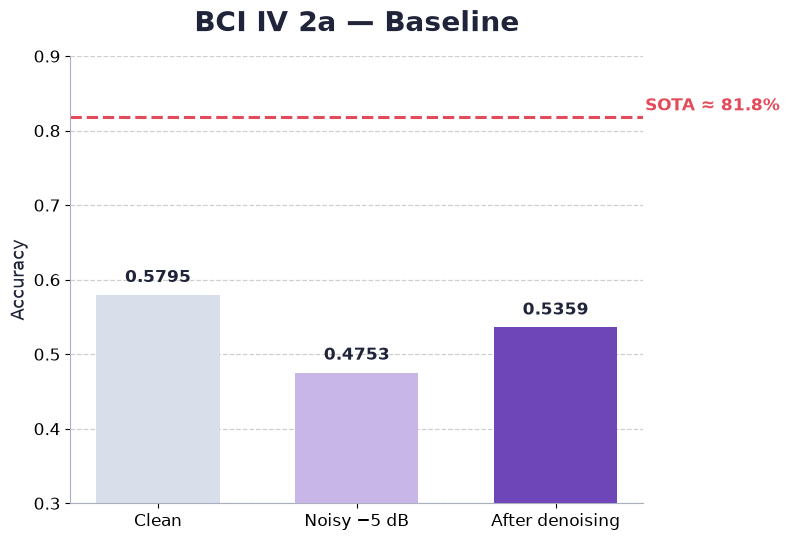

Saved: /Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/separate_plots/bci_baseline_sota.png


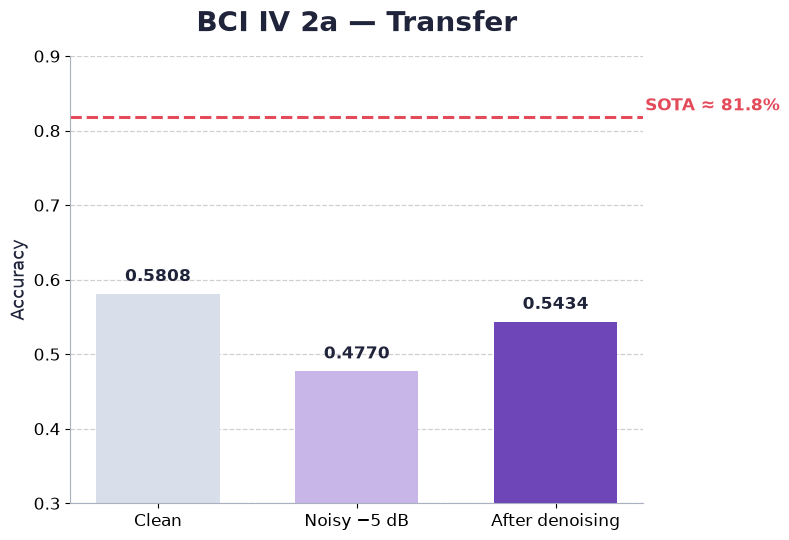

Saved: /Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/separate_plots/bci_transfer_sota.png


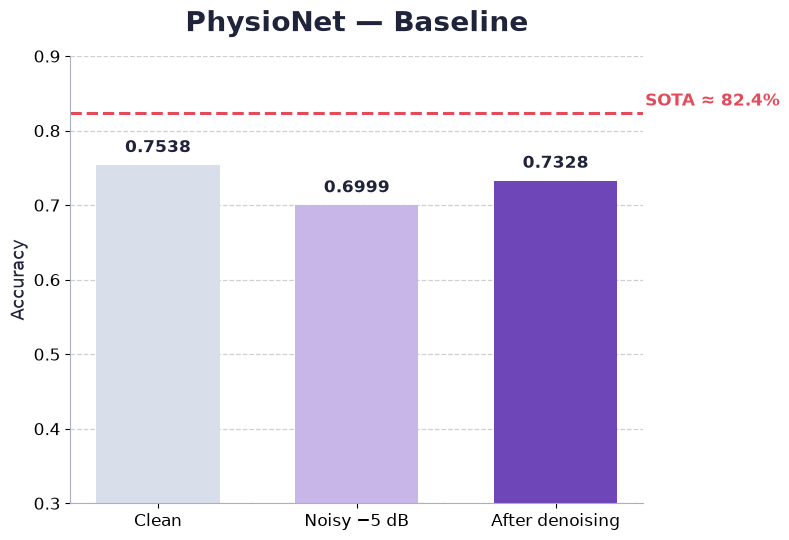

Saved: /Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/separate_plots/physionet_baseline_sota.png


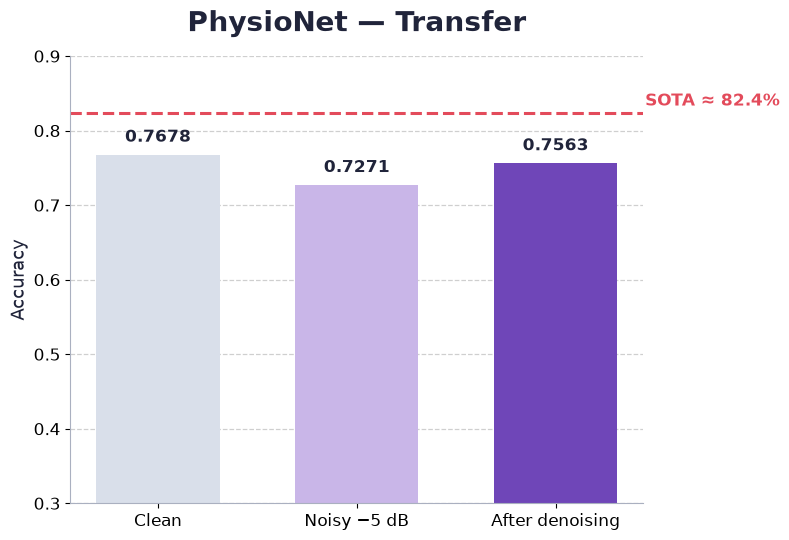

Saved: /Users/irina/Desktop/master project/results_v2/subject_independent_transfer_denoising/separate_plots/physionet_transfer_sota.png


In [96]:
# ============================================================
# 4 SEPARATE FIGURES:
# BCI / PhysioNet × Baseline / Transfer
# no combined slide, no +pp annotations
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# OUTPUT FOLDER
# ------------------------------------------------------------

OUT_DIR = os.path.join(
    BASE_DIR,
    "results_v2",
    "subject_independent_transfer_denoising",
    "separate_plots"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# DATA
# ------------------------------------------------------------

plots = [
    {
        "filename": "bci_baseline_sota.png",
        "title": "BCI IV 2a — Baseline",
        "clean": 0.5795,
        "noisy": 0.4753,
        "denoised": 0.5359,
        "sota": 0.8179,
        "sota_label": "SOTA ≈ 81.8%"
    },
    {
        "filename": "bci_transfer_sota.png",
        "title": "BCI IV 2a — Transfer",
        "clean": 0.5808,
        "noisy": 0.4770,
        "denoised": 0.5434,
        "sota": 0.8179,
        "sota_label": "SOTA ≈ 81.8%"
    },
    {
        "filename": "physionet_baseline_sota.png",
        "title": "PhysioNet — Baseline",
        "clean": 0.7538,
        "noisy": 0.6999,
        "denoised": 0.7328,
        "sota": 0.8243,
        "sota_label": "SOTA ≈ 82.4%"
    },
    {
        "filename": "physionet_transfer_sota.png",
        "title": "PhysioNet — Transfer",
        "clean": 0.7678,
        "noisy": 0.7271,
        "denoised": 0.7563,
        "sota": 0.8243,
        "sota_label": "SOTA ≈ 82.4%"
    },
]


# ------------------------------------------------------------
# STYLE
# ------------------------------------------------------------

TEXT = "#20243A"
CLEAN_COLOR = "#D9DFEA"
NOISY_COLOR = "#C9B6E8"
DENOISED_COLOR = "#6F46B8"
SOTA_COLOR = "#E34B5B"


# ------------------------------------------------------------
# DRAW EACH FIGURE SEPARATELY
# ------------------------------------------------------------

for item in plots:

    fig, ax = plt.subplots(
        figsize=(8, 5.5)
    )

    values = [
        item["clean"],
        item["noisy"],
        item["denoised"]
    ]

    labels = [
        "Clean",
        "Noisy −5 dB",
        "After denoising"
    ]

    colors = [
        CLEAN_COLOR,
        NOISY_COLOR,
        DENOISED_COLOR
    ]

    x = np.arange(len(values))

    bars = ax.bar(
        x,
        values,
        width=0.62,
        color=colors
    )

    # values above bars
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.012,
            f"{value:.4f}",
            ha="center",
            va="bottom",
            fontsize=12,
            fontweight="bold",
            color=TEXT
        )

    # SOTA line
    ax.axhline(
        y=item["sota"],
        linestyle="--",
        linewidth=2.2,
        color=SOTA_COLOR
    )

    ax.text(
        2.45,
        item["sota"] + 0.004,
        item["sota_label"],
        color=SOTA_COLOR,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="bottom"
    )

    # formatting
    ax.set_title(
        item["title"],
        fontsize=20,
        fontweight="bold",
        color=TEXT,
        pad=18
    )

    ax.set_ylabel(
        "Accuracy",
        fontsize=13,
        color=TEXT
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        labels,
        fontsize=12
    )

    ax.set_ylim(0.30, 0.90)
    ax.tick_params(axis="y", labelsize=12)

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.9,
        alpha=0.6
    )
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#AAB0C0")
    ax.spines["bottom"].set_color("#AAB0C0")

    plt.tight_layout()

    save_path = os.path.join(
        OUT_DIR,
        item["filename"]
    )

    plt.savefig(
        save_path,
        dpi=220,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close()

    print("Saved:", save_path)